# EDA · Fase 1: de los tres Excel al consumo diario de frío

**Qué hace este notebook.** Parte de los tres Excel de la planta y llega a una tabla `diario` con **una fila por día** y una columna `objetivo`: el consumo de frío (`Frio (Kw)`) del **día siguiente**, que es lo que el modelo va a predecir.

**Para quién es.** Para cualquiera del equipo que tenga que retomar el trabajo desde acá (preprocesamiento, modelado, informe) sin haber participado de este hito. Cada sección dice qué pregunta responde, muestra la evidencia y cierra con lo que se encontró y se decidió.

**Cómo leerlo.** De arriba abajo. El color de una tabla se usa solo cuando todas sus columnas miden lo mismo: ahí, el mismo valor tiene siempre el mismo color y cuanto más oscura la celda, mayor el valor (las escalas de conteos arrancan en 0). Si las columnas mezclan unidades, la tabla va sin color. En las diferencias con signo, azul es "de menos", rojo "de más" y gris es cero. El código reutilizable no está acá: vive en `src/auxiliar_functions.py` y el notebook lo importa.

**Requisitos.** Entorno `cervecera_env` activo y los tres Excel dentro de `data/` (no se versionan; ver README, sección "Datos"). Ejecutarlo completo tarda unos minutos, casi todo en leer los Excel.

## Índice

1. Preparación
2. Los tres archivos y sus hojas
3. Lectura de la hoja `Consolidado EE`
4. Cierre del día: 23:00 o 23:59
5. Diagnóstico de filas por fecha
6. Fechas con más de 25 filas
7. Los tres archivos juntos: períodos, solapes y diferencias
8. El calendario: fechas ausentes y bloques por mes
9. Evidencia de la hoja `Seguimiento Dia`
10. Decisiones sobre los bloques y los días inválidos
11. La tabla `diario`: una versión por bloque
12. El objetivo: el consumo del día siguiente
13. Pendientes

## Decisiones que salen de este notebook

| Código | Decisión | Dónde se justifica |
|---|---|---|
| **D1** | El consumo del día se toma de la última lectura (23:59), no de la de las 23:00. | Sección 4 |
| **D2** | Cada bloque de lecturas de 00:00 a 23:59 es un día distinto, aunque comparta fecha con otro. "Día siguiente" significa el bloque siguiente. | Secciones 6, 8, 9 y 10 |
| **D3** | Si un día está en dos Excel se usa la versión completa y plausible; si empatan, la del Excel más reciente. | Sección 7 |
| **D4** | Los días sin lectura de las 23:59 o con consumos del orden de millones son inválidos: se marcan y **no se imputan**. | Secciones 10 y 11 |

## 1. Preparación

Se importan las librerías y las funciones compartidas de `src/auxiliar_functions.py`. Las rutas son relativas a la carpeta `notebooks/`, así que el notebook se tiene que abrir desde ahí (VS Code y Jupyter lo hacen por defecto).

In [3]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

# Los scripts del TP importan como `from auxiliar_functions import ...`; acá se hace igual.
sys.path.append("../src")
from auxiliar_functions import (
    COLUMNA_CONSUMO,
    CONSUMO_MAXIMO_PLAUSIBLE,
    HORA_CIERRE,
    cierres_por_bloque,
    construir_diario,
    formatear_fechas,
    leer_consolidado_ee,
    mostrar_lado_a_lado,
    mostrar_lado_a_lado_simple,
    numerar_bloques,
    resumir_por_fecha,
    tabla_simple,
    unir_versiones,
)

DATA_DIR = Path("../data")
archivos = sorted(DATA_DIR.glob("Totalizadores Planta *.xlsx"))
assert len(archivos) == 3, "Faltan Excel en data/ (ver README, sección 'Datos')."

# Nombre corto de cada archivo, p. ej. "2020-2022". El orden alfabético es también el cronológico.
nombres = [archivo.stem.replace("Totalizadores Planta ", "") for archivo in archivos]
print("Archivos encontrados:", nombres)

Archivos encontrados: ['2020-2022', '2021-2023', '2022-2023']


## 2. Los tres archivos y sus hojas

**Pregunta:** ¿qué hojas tiene cada Excel? ¿Se pueden leer por posición?

Los tres archivos cubren períodos distintos que se solapan en el tiempo. Antes de leer nada hay que saber si todos tienen la misma estructura. Cada libro se abre una sola vez y se reutiliza después, porque abrir un Excel de 30 MB es lo lento.

In [4]:
libros = {nombre: pd.ExcelFile(archivo) for nombre, archivo in zip(nombres, archivos)}
hojas = {nombre: libro.sheet_names for nombre, libro in libros.items()}

# Todas las hojas que aparecen en algún archivo, en el orden en que aparecen.
orden_de_hojas = []
for lista in hojas.values():
    for hoja in lista:
        if hoja not in orden_de_hojas:
            orden_de_hojas.append(hoja)

cantidad = pd.DataFrame({"Cantidad de hojas": {nombre: len(lista) for nombre, lista in hojas.items()}})
presencia = pd.DataFrame(
    {nombre: [int(hoja in lista) for hoja in orden_de_hojas] for nombre, lista in hojas.items()},
    index=orden_de_hojas,
)

# La matriz de presencia usa una sola escala fija (0 a 1) para toda la tabla: así cada 1
# tiene el mismo color en cualquier columna. Con una escala por columna, una columna
# toda de unos quedaba sin color.
mostrar_lado_a_lado(
    [
        ("Cantidad de hojas por archivo", cantidad, {"vmin": 0}),
        ("Hojas presentes (1 = está, 0 = no está)", presencia, {"axis": None, "vmin": 0, "vmax": 1}),
    ],
    precision=0,
)

**Hallazgo.** Hay 15 hojas comunes a los tres archivos. El segundo trae una más, `Seguimiento Dia`, que los otros no tienen; por eso las cantidades son 15, 16 y 15. Las hojas se leen siempre **por nombre** y no por posición. En este notebook solo se usa `Consolidado EE`; el inventario del resto queda como pendiente (sección 13).

## 3. Lectura de la hoja `Consolidado EE`

**Pregunta:** ¿cómo es la hoja que contiene el objetivo y cómo se ve un día?

El objetivo, `Frio (Kw)`, está en la hoja `Consolidado EE`. La función `leer_consolidado_ee` la busca **por nombre** (no por posición, porque los archivos tienen distinta cantidad de hojas), descarta las filas vacías del final y convierte `DIA` a fecha. Es el paso lento: alrededor de un minuto por archivo.

In [5]:
tablas = {}
filas_sin_fecha = {}
for nombre, libro in libros.items():
    tablas[nombre], filas_sin_fecha[nombre] = leer_consolidado_ee(libro)

tabla_a = tablas[nombres[0]]  # el primer archivo se usa como ejemplo en las secciones 3 a 6

dimensiones = pd.DataFrame({"Cantidad": {"Filas con fecha": len(tabla_a), "Columnas": tabla_a.shape[1]}})
tipos = pd.DataFrame({"Tipo de dato": tabla_a.dtypes.astype(str)})

mostrar_lado_a_lado_simple(
    [(f"Dimensiones de la hoja (archivo {nombres[0]})", dimensiones), ("Columnas y tipo de dato", tipos)],
    precision=0,
)

,Cantidad
Filas con fecha,15575
Columnas,21
,Tipo de dato
DIA,datetime64[us]
HORA,str
Planta (Kw),float64
Elaboracion (Kw),float64
Bodega (Kw),float64
Cocina (Kw),float64
Envasado (Kw),float64


Un día de ejemplo, el 01/07/2020, con cinco lecturas y la primera del día siguiente. Se muestran solo cuatro de las 19 columnas numéricas.

In [6]:
horas_ejemplo = ["00:00:00", "04:00:00", "12:00:00", "23:00:00", "23:59:00"]
es_dia_ejemplo = (tabla_a["DIA"] == "2020-07-01") & tabla_a["HORA"].isin(horas_ejemplo)
es_inicio_del_siguiente = (tabla_a["DIA"] == "2020-07-02") & (tabla_a["HORA"] == "00:00:00")

ejemplo = tabla_a.loc[es_dia_ejemplo | es_inicio_del_siguiente, ["DIA", "HORA", "Planta (Kw)", "Sala Maq (Kw)", COLUMNA_CONSUMO, "KW Gral Planta"]]
ejemplo.index.name = "Fila del archivo"
display(tabla_simple(formatear_fechas(ejemplo), precision=0))

,DIA,HORA,Planta (Kw),Sala Maq (Kw),Frio (Kw),KW Gral Planta
Fila del archivo,,,,,,
0,2020-07-01,00:00:00,0,0,0,0
4,2020-07-01,04:00:00,2804,1701,1480,2978
12,2020-07-01,12:00:00,13387,8133,6872,14219
23,2020-07-01,23:00:00,25926,16304,13694,27716
24,2020-07-01,23:59:00,27637,17080,14325,29529
25,2020-07-02,00:00:00,0,0,0,0


**Hallazgo.** El primer archivo tiene 15.575 filas con fecha y 21 columnas: `DIA`, `HORA` y 19 variables numéricas en kW. Cada fila es una lectura horaria y los valores son **acumulados del día**: arrancan en 0 a las 00:00, crecen durante el día y se **reinician a medianoche**. Un día normal tiene 25 lecturas: 24 en punto (de 00:00 a 23:00) y una de cierre a las 23:59. El consumo del día es el acumulado de esa última lectura, no una suma de las horas.

## 4. Cierre del día: 23:00 o 23:59

**Pregunta:** ¿el consumo diario se toma de la lectura de las 23:00 o de la de las 23:59?

La consigna exige elegir una, aplicarla en todo el trabajo y justificarla. **Decisión D1: 23:59.** Lo que se quiere predecir es el consumo de un **día entero**; la lectura de las 23:00 deja afuera la última hora. Para ponerle número a lo que se pierde, se compara en cada día del primer archivo el acumulado de las 23:00 con el de las 23:59.

In [7]:
bloque_a = numerar_bloques(tabla_a)
es_23 = tabla_a["HORA"] == "23:00:00"
es_cierre = tabla_a["HORA"] >= HORA_CIERRE

# Un valor por bloque diario (la última lectura que cumple cada condición).
consumo_23 = tabla_a.loc[es_23, COLUMNA_CONSUMO].groupby(bloque_a[es_23]).last()
consumo_cierre = tabla_a.loc[es_cierre, COLUMNA_CONSUMO].groupby(bloque_a[es_cierre]).last()

comparacion_cierre = pd.DataFrame({"a las 23:00": consumo_23, "a las 23:59": consumo_cierre}).dropna()
# Se excluyen los errores del orden de millones: no dicen nada de la última hora.
comparacion_cierre = comparacion_cierre[comparacion_cierre["a las 23:59"] <= CONSUMO_MAXIMO_PLAUSIBLE]
comparacion_cierre["lo que se pierde (kW)"] = comparacion_cierre["a las 23:59"] - comparacion_cierre["a las 23:00"]
comparacion_cierre["% del total del día"] = 100 * comparacion_cierre["lo que se pierde (kW)"] / comparacion_cierre["a las 23:59"]

resumen_cierre = comparacion_cierre.describe(percentiles=[0.1, 0.5, 0.9]).loc[["mean", "10%", "50%", "90%"]]
resumen_cierre.index = ["promedio", "percentil 10", "mediana", "percentil 90"]

print("Días comparados:", len(comparacion_cierre))
# Sin color: las columnas mezclan kW y porcentajes, y un gradiente compartiría escala entre unidades distintas.
mostrar_lado_a_lado_simple([("Lo que se pierde al cortar el día a las 23:00 (primer archivo)", resumen_cierre)], precision=1)

Días comparados: 606


,a las 23:00,a las 23:59,lo que se pierde (kW),% del total del día
promedio,23005.2,24015.9,1010.7,4.2
percentil 10,11633.0,12105.5,470.5,2.9
mediana,23687.5,24825.5,960.5,4.0
percentil 90,32441.5,33782.5,1496.0,5.5


**Hallazgo.** Cortar a las 23:00 deja afuera, en promedio, **1.011 kW** de los 24.016 kW del día (**4,2 %**). La mediana es 961 kW (4,0 %) y en el 80 % central de los días va de 471 kW (2,9 %) a 1.496 kW (5,5 %). Se compararon 606 días del primer archivo. Es una hora entera de consumo, no un error de redondeo, y siempre en el mismo sentido: la lectura de las 23:00 **subestima** el día.

**D1: se usa la lectura de las 23:59.** Algunas lecturas de cierre llevan unos segundos de diferencia (23:59:01 o 23:59:59) y se tratan igual: por eso la condición del código es "hora mayor o igual a 23:59:00".

## 5. Diagnóstico de filas por fecha

**Pregunta:** ¿cuántas lecturas tiene cada fecha y a qué hora termina el día?

La consigna pide verificar que **ninguna fecha tenga más de 25 registros** antes de agregar, y detectar los días con menos de 24 lecturas. Se hace con el primer archivo; los otros dos se revisan en la sección 7.

In [8]:
resumen_a = resumir_por_fecha(tabla_a)

filas_por_fecha = resumen_a["filas"].value_counts().sort_index().rename_axis("Filas en la fecha").to_frame("Cantidad de fechas")
ultima_lectura = resumen_a["ultima_hora"].value_counts().rename_axis("Última lectura del día").to_frame("Cantidad de fechas")
vacias = pd.DataFrame({"Filas vacías al final de la hoja": filas_sin_fecha})

# Son conteos: la escala arranca en 0 para que 134 y 479 no parezcan "claro y oscuro" por estirarse entre sí.
desde_cero = {"vmin": 0}
mostrar_lado_a_lado(
    [
        (f"Filas por fecha (archivo {nombres[0]})", filas_por_fecha, desde_cero),
        ("Hora de la última lectura", ultima_lectura, desde_cero),
        ("Filas sin fecha descartadas, por archivo", vacias, desde_cero),
    ],
    precision=0,
)

,Cantidad de fechas
Filas en la fecha,
8,1
23,2
24,5
25,596
50,5
51,1
100,2
,Cantidad de fechas
Última lectura del día,


Las fechas "raras": las que no tienen 25 filas o cuya última lectura es anterior a las 23:59.

In [9]:
raras = resumen_a[(resumen_a["filas"] != 25) | (resumen_a["ultima_hora"] < HORA_CIERRE)]
raras = raras.rename(columns={"filas": "Filas", "ultima_hora": "Última lectura"})
display(tabla_simple(formatear_fechas(raras), precision=0))

,Filas,Última lectura
DIA,,
2020-08-05,24,23:59:00
2020-09-30,50,23:59:00
2020-10-15,24,23:59:00
2020-11-30,50,23:59:00
2021-02-28,100,23:59:00
2021-04-30,50,23:59:00
2021-06-30,51,23:59:59
2021-07-13,23,23:00:00
2021-09-30,50,23:59:00


**Hallazgo.** De las 612 fechas del primer archivo, 596 tienen las 25 lecturas esperadas. Las otras se reparten así: 5 con 24 lecturas, 2 con 23 y 1 con solo 8, y **8 con más de 25** (50, 51 o 100), que rompen la regla de la consigna y se analizan en la sección 6.

En 601 fechas la última lectura es las 23:59:00; en 8 es 23:59:01 o 23:59:59 (el mismo cierre con unos segundos de diferencia); en 2 es las 23:00 y en 1 las 07:00. Además, cada hoja termina con filas vacías (479, 134 y 2 según el archivo), que se descartan.

Las lecturas que faltan **a mitad del día** no afectan al consumo diario, porque el valor es acumulado: solo importa que exista la lectura de cierre.

## 6. Fechas con más de 25 filas

**Pregunta:** ¿por qué hay fechas con 50, 51 o 100 filas? ¿Son copias, errores o días distintos?

Un **bloque** es un día completo de lecturas, de 00:00 a 23:59. Un bloque nuevo empieza cada vez que la hora retrocede respecto de la fila anterior (`numerar_bloques`); se usa la hora y no "cada 25 filas" porque hay días con lecturas de más o de menos.

In [10]:
cierres = {nombre: cierres_por_bloque(tabla, nombre) for nombre, tabla in tablas.items()}
bloques_por_fecha = cierres[nombres[0]].groupby("DIA").size()

repetidas = resumen_a[resumen_a["filas"] > 25].copy()
repetidas["bloques"] = bloques_por_fecha[repetidas.index]
repetidas["es_fin_de_mes"] = pd.Series(repetidas.index.is_month_end, index=repetidas.index).map({True: "Sí", False: "No"})
repetidas = repetidas.rename(columns={"filas": "Filas", "ultima_hora": "Última lectura", "bloques": "Bloques", "es_fin_de_mes": "¿Fin de mes?"})
display(tabla_simple(formatear_fechas(repetidas), precision=0))

,Filas,Última lectura,Bloques,¿Fin de mes?
DIA,,,,
2020-09-30,50,23:59:00,2,Sí
2020-11-30,50,23:59:00,2,Sí
2021-02-28,100,23:59:00,4,Sí
2021-04-30,50,23:59:00,2,Sí
2021-06-30,51,23:59:59,2,Sí
2021-09-30,50,23:59:00,2,Sí
2021-11-30,50,23:59:00,2,Sí
2022-02-28,100,23:59:00,4,Sí


Un caso concreto: el 30/09/2020 (50 filas). Se muestran la primera lectura, la de las 23:00 y la de cierre de cada bloque.

In [11]:
dia = tabla_a[tabla_a["DIA"] == "2020-09-30"]
numero = numerar_bloques(tabla_a)[dia.index]
dia = dia.assign(Bloque=numero - numero.min())

ejemplo_repetido = dia.loc[dia["HORA"].isin(["00:00:00", "23:00:00", "23:59:00"]), ["DIA", "Bloque", "HORA", COLUMNA_CONSUMO]]
ejemplo_repetido.index.name = "Fila del archivo"
display(tabla_simple(formatear_fechas(ejemplo_repetido), precision=0))

,DIA,Bloque,HORA,Frio (Kw)
Fila del archivo,,,,
2199,2020-09-30,0,00:00:00,0
2222,2020-09-30,0,23:00:00,28609
2223,2020-09-30,0,23:59:00,29623
2224,2020-09-30,1,00:00:00,0
2247,2020-09-30,1,23:00:00,24829
2248,2020-09-30,1,23:59:00,25558


**Hallazgo.** Las 8 fechas con más de 25 filas son **todas fin de mes de un mes corto** (28/02, 30/04, 30/06, 30/09 y 30/11). Las de 50 filas tienen 2 bloques; las de 100, febrero, tienen 4, como si febrero tuviera 31 días; el 30/06/2021 tiene 2 bloques más una lectura suelta (51 filas).

No son copias: el 30/09/2020 contiene dos días completos, cada uno con su reinicio a 0 a las 00:00 y su propio cierre (29.623 y 25.558). Esto sugiere que para esas fechas el archivo trae más de un día; las secciones 8 y 9 lo verifican.

## 7. Los tres archivos juntos: períodos, solapes y diferencias

**Pregunta:** ¿qué período cubre cada Excel, cuánto se solapan y, en los días que están en dos, ¿dicen lo mismo?

La consigna pide cuantificar las fechas repetidas entre archivos y definir una regla de desempate. Como cada bloque puede repetirse, se lo identifica con la pareja **(fecha rotulada, número de bloque dentro de esa fecha)**.

In [12]:
resumen_archivos = pd.DataFrame({
    "Primera fecha": {n: c["DIA"].min() for n, c in cierres.items()},
    "Última fecha": {n: c["DIA"].max() for n, c in cierres.items()},
    "Fechas distintas": {n: c["DIA"].nunique() for n, c in cierres.items()},
    "Bloques diarios": {n: len(c) for n, c in cierres.items()},
})

fechas = {n: set(c["DIA"]) for n, c in cierres.items()}
pares = [(nombres[0], nombres[1]), (nombres[1], nombres[2]), (nombres[0], nombres[2])]
solapes = pd.DataFrame({"Fechas en común": {f"{a} y {b}": len(fechas[a] & fechas[b]) for a, b in pares}})

mostrar_lado_a_lado_simple(
    [("Período que cubre cada archivo", formatear_fechas(resumen_archivos)), ("Solape entre archivos", solapes)],
    precision=0,
)

Ahora se compara, para cada bloque que está en dos archivos, el consumo de cierre de la versión más antigua con el de la más reciente.

In [13]:
todos = pd.concat(cierres.values(), ignore_index=True)
claves = ["DIA", "bloque"]

repetidos = todos[todos.duplicated(claves, keep=False)].sort_values(claves + ["archivo"])
antigua = repetidos.drop_duplicates(claves, keep="first").set_index(claves)
reciente = repetidos.drop_duplicates(claves, keep="last").set_index(claves)

comparacion = pd.DataFrame({
    "Archivo antiguo": antigua["archivo"],
    "Consumo antiguo": antigua[COLUMNA_CONSUMO],
    "Archivo reciente": reciente["archivo"],
    "Consumo reciente": reciente[COLUMNA_CONSUMO],
    "ambos_completos": antigua["completo"] & reciente["completo"],
})
comparacion["Diferencia"] = comparacion["Consumo antiguo"] - comparacion["Consumo reciente"]

par = comparacion["Archivo antiguo"] + " y " + comparacion["Archivo reciente"]
son_distintos = comparacion["ambos_completos"] & (comparacion["Diferencia"] != 0)
resumen_comparacion = pd.DataFrame({
    "Bloques en común": par.value_counts(),
    "Completos en ambos": par[comparacion["ambos_completos"]].value_counts(),
    "Con distinto consumo de cierre": par[son_distintos].value_counts(),
}).fillna(0).astype(int)

# Las tres columnas cuentan bloques, así que comparten escala (axis=None).
mostrar_lado_a_lado(
    [("Bloques que están en dos archivos, por pareja de archivos", resumen_comparacion, {"axis": None, "vmin": 0})],
    precision=0,
)

,Bloques en común,Completos en ambos,Con distinto consumo de cierre
2020-2022 y 2021-2023,259,256,5
2021-2023 y 2022-2023,249,247,0


Los bloques con distinto consumo de cierre:

In [14]:
discrepancias = comparacion[son_distintos].drop(columns="ambos_completos").reset_index()
display(tabla_simple(formatear_fechas(discrepancias), precision=0))

,DIA,bloque,Archivo antiguo,Consumo antiguo,Archivo reciente,Consumo reciente,Diferencia
0,2021-07-28,0,2020-2022,2900770,2021-2023,30764,2870006
1,2021-08-25,0,2020-2022,2907122,2021-2023,37122,2870000
2,2021-11-28,0,2020-2022,6155928,2021-2023,25719,6130209
3,2022-02-02,0,2020-2022,52655,2021-2023,19887,32768
4,2022-02-18,0,2020-2022,8861470,2021-2023,21470,8840000


**Hallazgo.** Los tres períodos se encadenan sin huecos de cobertura: el primero llega al 16/03/2022, el segundo cubre del 01/07/2021 al 06/03/2023 y el tercero del 01/07/2022 al 26/10/2023. El primero y el segundo comparten 259 bloques; el segundo y el tercero, 249; el primero y el tercero no se tocan.

En los bloques que están en dos archivos, **el consumo de cierre coincide en todos los casos menos 5**, todos entre el primer y el segundo Excel. Los bloques completos en ambos son 256 de 259 y 247 de 249; el resto está cortado o sin lectura de las 23:59.

En esas 5 el primer archivo trae un error: en cuatro, un consumo del orden de millones (diferencias de 2.870.000, 2.870.006 y 8.840.000, casi redondas, y 6.130.209 el 28/11/2021); en la quinta, el 02/02/2022, 52.655 contra 19.887, una diferencia de exactamente **32.768** (2 elevado a la 15, cifra típica de errores informáticos, no de consumo). En las 5 el valor del segundo archivo está dentro del rango normal.

**D3:** ante dos versiones se elige la completa y plausible, y si empatan la del archivo más reciente.

## 8. El calendario: fechas ausentes y bloques por mes

**Pregunta:** ¿las fechas del archivo coinciden con el calendario? ¿Falta algún día?

Primero, qué fechas del calendario no aparecen en cada archivo dentro de su propio período. Después, cuántos bloques tiene cada mes comparado con los días que realmente tiene, en los dos años completos que cubren los datos (2021 y 2022).

In [15]:
ausentes = {}
for nombre, cierre in cierres.items():
    calendario = pd.date_range(cierre["DIA"].min(), cierre["DIA"].max())
    ausentes[nombre] = calendario.difference(pd.DatetimeIndex(cierre["DIA"].unique()))

fechas_ausentes = pd.DataFrame({
    "Cantidad": {n: len(a) for n, a in ausentes.items()},
    "Fechas ausentes": {n: ", ".join(a.strftime("%d/%m/%Y")) for n, a in ausentes.items()},
})
display(tabla_simple(fechas_ausentes, precision=0))

,Cantidad,Fechas ausentes
2020-2022,12,"29/08/2020, 30/08/2020, 31/08/2020, 31/10/2020, 31/12/2020, 31/03/2021, 31/05/2021, 29/08/2021, 30/08/2021, 31/08/2021, 31/10/2021, 31/12/2021"
2021-2023,12,"29/08/2021, 30/08/2021, 31/08/2021, 31/10/2021, 31/12/2021, 31/03/2022, 31/05/2022, 29/08/2022, 30/08/2022, 31/08/2022, 31/10/2022, 31/12/2022"
2022-2023,9,"29/08/2022, 30/08/2022, 31/08/2022, 31/10/2022, 31/12/2022, 31/03/2023, 31/05/2023, 30/08/2023, 31/08/2023"


In [16]:
unicos = todos.drop_duplicates(["DIA", "bloque"])
bloques_por_mes = unicos.groupby([unicos["DIA"].dt.year, unicos["DIA"].dt.month]).size().unstack(0)

meses = ["Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio", "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre"]
tabla_meses = pd.DataFrame(index=range(1, 13))
tabla_meses["Días del mes"] = [pd.Period(f"2021-{mes:02d}").days_in_month for mes in range(1, 13)]
for anio in (2021, 2022):
    tabla_meses[f"Bloques {anio}"] = bloques_por_mes[anio].astype(int)
    tabla_meses[f"Diferencia {anio}"] = tabla_meses[f"Bloques {anio}"] - tabla_meses["Días del mes"]
tabla_meses.index = meses

columnas_bloques = ["Días del mes", "Bloques 2021", "Bloques 2022"]
columnas_diferencia = ["Diferencia 2021", "Diferencia 2022"]
suma_del_anio = tabla_meses.sum().to_frame("Suma del año").T

# El color va solo donde dice algo: las cantidades (28 a 31) se leen mejor como números y
# un gradiente estiraría una diferencia de tres días hasta parecer enorme. Las diferencias
# sí llevan una paleta divergente centrada en 0 (azul = bloques de menos, rojo = de más).
mostrar_lado_a_lado(
    [
        ("Días del mes y bloques del archivo", tabla_meses[columnas_bloques], {"sin_color": True}),
        ("Diferencia (bloques - días reales)", tabla_meses[columnas_diferencia], {"axis": None, "cmap": "coolwarm", "vmin": -3, "vmax": 3}),
        ("Suma de cada columna en el año", suma_del_anio, {"sin_color": True}),
    ],
    precision=0,
)

,Días del mes,Bloques 2021,Bloques 2022
Enero,31,31,31
Febrero,28,31,31
Marzo,31,30,30
Abril,30,31,31
Mayo,31,30,30
Junio,30,31,31
Julio,31,31,31
Agosto,31,28,28
Septiembre,30,31,31
Octubre,31,30,30


**Hallazgo.** Las fechas ausentes se repiten igual cada año: el 31 de marzo, mayo, octubre y diciembre, y los días 29, 30 y 31 de agosto (en el tercer archivo, en 2023, faltan solo el 30 y el 31 de agosto). Al revés, los meses cortos tienen bloques de más: febrero tiene 31 en lugar de 28, y abril, junio, septiembre y noviembre tienen 31 en lugar de 30.

**Los desvíos se compensan:** la suma de las diferencias da 0 y cada año (2021 y 2022) tiene exactamente 365 bloques, igual que sus 365 días. Una compensación exacta como esa es difícil de atribuir al azar. La lectura más razonable, aunque **no demostrada**, es que los bloques son días consecutivos reales y que las etiquetas de fecha están desfasadas unos días en algunos meses.

## 9. Evidencia de la hoja `Seguimiento Dia`

**Pregunta:** ¿hay en el propio Excel alguna señal de cómo trata la planta a los bloques que repiten fecha?

El segundo archivo (y solo ese) trae una hoja extra, `Seguimiento Dia`, con una columna `Ultimo Dato del Dia` que vale 1 en la última lectura de cada día y 0 en el resto. Se la compara con los bloques que encontramos.

In [17]:
seguimiento = pd.read_excel(libros[nombres[1]], sheet_name="Seguimiento Dia")
marcas = seguimiento[seguimiento["Ultimo Dato del Dia"] == 1]
bloques_b = cierres[nombres[1]]

evidencia = pd.DataFrame({"Cantidad": {
    "Filas de la hoja Seguimiento Dia": len(seguimiento),
    "Filas de Consolidado EE (sin las vacías)": len(tablas[nombres[1]]),
    "Marcas de 'Ultimo Dato del Dia'": len(marcas),
    "Bloques diarios del segundo archivo": len(bloques_b),
    "Fechas distintas del segundo archivo": bloques_b["DIA"].nunique(),
    "Marcas en una hora anterior a las 23:59": int((marcas["HORA"].astype(str) < HORA_CIERRE).sum()),
}})
display(tabla_simple(evidencia, precision=0))

,Cantidad
Filas de la hoja Seguimiento Dia,15316
Filas de Consolidado EE (sin las vacías),15316
Marcas de 'Ultimo Dato del Dia',614
Bloques diarios del segundo archivo,614
Fechas distintas del segundo archivo,602
Marcas en una hora anterior a las 23:59,4


**Hallazgo.** La hoja `Seguimiento Dia` tiene exactamente las mismas filas que `Consolidado EE` del segundo archivo (15.316) y **614 marcas** de último dato, igual a los 614 bloques y no a las 602 fechas distintas: para la planta, cada bloque cuenta como un día. Cuatro de esas marcas caen antes de las 23:59, o sea que la hoja marca el final de **cada bloque**, también el de los días cortados.

Hay que tomarlo como una pista y no como una prueba independiente: tiene las mismas filas que `Consolidado EE`, probablemente se calcula a partir de ellas, y no trae ninguna fecha real distinta.

## 10. Decisiones sobre los bloques y los días inválidos

**D2. Los bloques son días distintos.** Cada bloque de 00:00 a 23:59 se trata como un día, y "día siguiente" es el bloque siguiente del archivo, no la fecha siguiente del calendario. Lo respaldan: los bloques repetidos tienen valores propios y coinciden entre archivos (sección 7), el total de bloques por año es igual a los días del año (sección 8) y la hoja `Seguimiento Dia` marca cada bloque como un día (sección 9). **Lo que no sabemos** es qué fecha real le corresponde a cada bloque; las etiquetas de fecha pueden estar corridas unos días. Por eso la fecha rotulada se conserva solo como dato informativo y las variables de calendario (día de la semana, mes) hay que usarlas con cuidado. Queda como consulta para la cátedra.

| Alternativa | Por qué se descartó |
|---|---|
| Quedarse con el primer bloque de cada fecha y tirar los demás | Descarta días reales (unos 7 por año) y no corrige las fechas corridas. |
| Reasignar fechas consecutivas según el orden del archivo | Obliga a inventar fechas sin poder comprobarlas. |

**D4. Días inválidos.** Un día es **inválido** si no tiene lectura de las 23:59 (el acumulado del día queda incompleto) o si su consumo supera el corte provisorio de `CONSUMO_MAXIMO_PLAUSIBLE` (errores del orden de millones). No se imputa el valor: se marca `valido = False` y el consumo queda vacío. Imputar el objetivo equivaldría a medir el error del modelo contra un número fabricado por nosotros. Qué hacer con esas filas al entrenar se decide en preprocesamiento. Desde el ADR 0005 también es **inválido** un día con un salto no corregido del contador, con un reinicio tardío o que arranca con más de 100 kW (sección 16).

**D3. Versión elegida.** Si un bloque está en dos Excel, se toma la versión que llega a las 23:59 y tiene un consumo plausible; si empatan, la del archivo más reciente (en las discrepancias de la sección 7 el posterior tenía siempre el valor correcto).

## 11. La tabla `diario`: una versión por bloque

**Pregunta:** aplicando D3, ¿cuántos días únicos quedan y de qué archivo sale cada uno?

In [18]:
mejores = unir_versiones(todos)

versiones = todos.groupby(["DIA", "bloque"]).size().value_counts().sort_index().rename_axis("Archivos que lo traen").to_frame("Cantidad de bloques")
elegidos = mejores["archivo"].value_counts().sort_index().rename_axis("Archivo").to_frame("Bloques elegidos")

mostrar_lado_a_lado(
    [
        ("Cuántos archivos traen cada bloque", versiones, {"vmin": 0}),
        ("De qué archivo se tomó cada bloque", elegidos, {"vmin": 0}),
    ],
    precision=0,
)
print("Bloques únicos (días de la serie):", len(mejores))

,Cantidad de bloques
Archivos que lo traen,
1,704
2,508
,Bloques elegidos
Archivo,
2020-2022,365
2021-2023,365
2022-2023,482


Bloques únicos (días de la serie): 1212


Los días inválidos según D4 (sin lectura de las 23:59 o con consumo implausible), y la comprobación del 02/02/2022, el caso en que el primer archivo tenía 52.655 y el segundo 19.887:

In [19]:
invalidos = mejores.loc[~mejores["completo"] | ~mejores["plausible"], ["DIA", "bloque", "HORA", COLUMNA_CONSUMO, "filas", "archivo"]]
invalidos = invalidos.rename(columns={"bloque": "Bloque", "HORA": "Última lectura", "filas": "Lecturas", "archivo": "Archivo elegido"})
display(tabla_simple(formatear_fechas(invalidos.reset_index(drop=True)), precision=0))

control = mejores.loc[mejores["DIA"] == "2022-02-02", ["DIA", "bloque", COLUMNA_CONSUMO, "archivo"]]
display(tabla_simple(formatear_fechas(control.reset_index(drop=True)), precision=0))

,DIA,Bloque,Última lectura,Frio (Kw),Lecturas,Archivo elegido
0,2021-04-30,1,23:59:00,5572801,25,2020-2022
1,2021-07-13,0,23:00:00,33704,23,2021-2023
2,2022-03-02,0,23:00:00,19294,24,2021-2023
3,2023-02-28,0,23:00:00,15279,24,2022-2023
4,2023-04-13,0,19:00:00,14315,20,2022-2023
5,2023-04-19,0,16:00:00,13439,17,2022-2023
6,2023-10-26,0,07:00:00,3124,8,2022-2023


,DIA,bloque,Frio (Kw),archivo
0,2022-02-02,0,19887,2021-2023


**Hallazgo.** La serie tiene **1.212 días únicos** (bloques): 704 están en un solo archivo y 508 en dos. Como ante un empate gana el archivo más reciente, el tercero aporta todos sus bloques (482), el segundo los que el tercero no trae (365) y el primero los que el segundo no trae (365).

Con el primer filtro (D4) los **7 días inválidos** son: el segundo bloque del 30/04/2021, con un consumo de 5,57 millones que está solo en el primer archivo (no hay otra versión que lo corrija), y seis días sin lectura de las 23:59 (13/07/2021, 02/03/2022, 28/02/2023, 13/04/2023, 19/04/2023 y 26/10/2023, este último el último día del dataset, cortado a las 07:00). Con la regla ampliada del ADR 0005 (sección 16) los inválidos pasan a ser 25.

La comprobación del 02/02/2022 confirma D3: el bloque sale del segundo archivo con 19.887, no con el 52.655 del primero.

## 12. El objetivo: el consumo del día siguiente

**Pregunta:** ¿cómo se arma la variable a predecir?

El modelo trabaja a las 23:59 de cada día: con lo que ya se sabe de hoy, predice cuánto va a consumir el frío **mañana**. Una fila de la tabla es "lo conocido al cierre del día D" y su objetivo es el consumo del día D+1. Predecir el de hoy con datos de hoy sería predecir algo que ya se conoce (fuga de información).

`construir_diario` agrega tres columnas: `valido` (D4), `consumo_dia` (el consumo de cierre, vacío si el día es inválido) y `objetivo` (`consumo_dia` corrido una fila hacia arriba con `shift(-1)`).

In [20]:
diario = construir_diario(mejores)

conteo = pd.DataFrame({"Cantidad": {
    "Días totales (bloques)": len(diario),
    "Días válidos": int(diario["valido"].sum()),
    "Días inválidos": int((~diario["valido"]).sum()),
    "Filas con objetivo": int(diario["objetivo"].notna().sum()),
    "Filas sin objetivo": int(diario["objetivo"].isna().sum()),
}})

muestra = diario.loc[:5, ["DIA", "bloque", "consumo_dia", "objetivo"]]
sin_objetivo = diario.loc[diario["objetivo"].isna(), ["DIA", "bloque", "consumo_dia", "valido"]]

mostrar_lado_a_lado_simple(
    [
        ("Resumen", conteo),
        ("Las primeras filas: el objetivo es el consumo de la fila siguiente", formatear_fechas(muestra)),
        ("Filas sin objetivo", formatear_fechas(sin_objetivo)),
    ],
    precision=0,
)

In [21]:
from auxiliar_functions import UMBRAL_LECTURA_INICIAL

motivos = pd.DataFrame({"Días": {
    "Total de días": len(diario),
    "Válidos": int(diario["valido"].sum()),
    "Inválidos": int((~diario["valido"]).sum()),
    "… no llega a las 23:59": int((~diario["completo"]).sum()),
    "… consumo mayor al corte de millones": int((~diario["plausible"]).sum()),
    "… salto no corregido": int((diario["tipo_falla"] == "Salto no corregido").sum()),
    "… reinicio tardío": int((diario["tipo_falla"] == "Reinicio tardío").sum()),
    f"… arranca con más de {UMBRAL_LECTURA_INICIAL}": int((diario["lectura_inicial"] > UMBRAL_LECTURA_INICIAL).sum()),
    "Filas con objetivo": int(diario["objetivo"].notna().sum()),
}})
mostrar_lado_a_lado_simple([("Resultado de la regla de validez", motivos)], precision=0)


,Días
Total de días,1212
Válidos,1187
Inválidos,25
… no llega a las 23:59,6
… consumo mayor al corte de millones,1
… salto no corregido,16
… reinicio tardío,1
… arranca con más de 100,3
Filas con objetivo,1186


**Hallazgo.** De los 1.212 días, **1.187 son válidos y 25 inválidos**. Los inválidos son los 7 de la regla D4 (seis sin lectura de las 23:59 y uno de millones) más 18 que detecta la regla del ADR 0005 por la evolución del contador dentro del día (sección 16): saltos no corregidos, un reinicio tardío y días que arrancan distinto de cero. Hay **1.186 filas con objetivo** y 26 sin él: los días que preceden a un día inválido (su "mañana" no es confiable) y el último día del dataset (inválido y sin día siguiente).

Esas 26 filas se conservan en la tabla, con su consumo propio, porque más adelante pueden servir de historia para otros días (valores de días anteriores como variables de entrada); recién se descartan al entrenar. En la muestra de arriba se ve la mecánica: el objetivo de cada fila es el `consumo_dia` de la siguiente.

## 13. Pendientes

**Valores extremos.** Resuelto en la sección 16 (ADR 0005): el corte de `CONSUMO_MAXIMO_PLAUSIBLE` solo separaba los errores de millones, y el análisis de la evolución del contador dentro del día detectó otras fallas que también se marcan inválidas. Con esa regla, el consumo de los días válidos se resume así:

In [22]:
resumen_consumo = diario["consumo_dia"].describe(percentiles=[0.05, 0.5, 0.95]).to_frame("consumo_dia")
resumen_consumo.index = ["días", "promedio", "desvío", "mínimo", "percentil 5", "mediana", "percentil 95", "máximo"]
mas_altos = diario.nlargest(5, "consumo_dia")[["DIA", "bloque", "consumo_dia"]]

mostrar_lado_a_lado_simple(
    [("Consumo de cierre de los días válidos", resumen_consumo), ("Los 5 días válidos con mayor consumo", formatear_fechas(mas_altos))],
    precision=0,
)

| Pendiente | Detalle |
|---|---|
| Confirmar dudas con profes | Fechas repetidas a fin de mes y bloques por mes que no coinciden con los días reales; nombres de los Excel distintos a los de la consigna; formato del informe; si se aceptan `tests/` y `docs/`. |
| Baselines | Persistencia y media móvil de 7 días, con su error. |
| Otras hojas | Inventario hoja por hoja y alineación con `diario` por la clave (fecha rotulada, bloque); correlaciones y variables que se parecen demasiado al objetivo. |
| Gráficos del objetivo | Histograma y Q-Q plot del objetivo, las 5 variables más correlacionadas y el consumo por área. |
| Huella de los Excel | `data/checksums.json` con SHA-256 por bloques. |

Los roles son los del plan: **A** Datos y Pipeline, **B** Análisis e Informe, **C** Modelado y MLOps.

## 14. Efecto del día de la semana

**Pregunta:** ¿el consumo de frío cambia según el día de la semana? Si el efecto es despreciable, una consigna del TP pide decirlo con el número y descartarlo.

**Paso 1: Resumen de la tabla**

In [23]:
columnas = ["DIA", "bloque", "archivo", "filas", COLUMNA_CONSUMO, "valido", "consumo_dia", "objetivo"]
display(tabla_simple(formatear_fechas(diario[columnas].head()), precision=0))

print(f"Filas: {diario.shape[0]}  |  Columnas: {diario.shape[1]}")
print(list(diario.columns))


,DIA,bloque,archivo,filas,Frio (Kw),valido,consumo_dia,objetivo
0,2020-07-01,0,2020-2022,25,14325,True,14325,23954
1,2020-07-02,0,2020-2022,25,23954,True,23954,28268
2,2020-07-03,0,2020-2022,25,28268,True,28268,24246
3,2020-07-04,0,2020-2022,25,24246,True,24246,29885
4,2020-07-05,0,2020-2022,25,29885,True,29885,24449


Filas: 1212  |  Columnas: 33
['DIA', 'HORA', 'Planta (Kw)', 'Elaboracion (Kw)', 'Bodega (Kw)', 'Cocina (Kw)', 'Envasado (Kw)', 'Linea 2 (Kw)', 'Linea 3 (Kw)', 'Linea 4 (Kw)', 'Servicios (Kw)', 'Sala Maq (Kw)', 'Aire (Kw)', 'Calderas (Kw)', 'Efluentes (Kw)', 'Frio (Kw)', 'Pta Agua / Eflu (Kw)', 'Prod Agua (Kw)', 'Resto Serv (Kw)', 'Restos Planta (Kw)', 'KW Gral Planta', 'lectura_inicial', 'mayor_incremento', 'menor_incremento', 'filas', 'bloque', 'archivo', 'completo', 'plausible', 'tipo_falla', 'valido', 'consumo_dia', 'objetivo']


**Paso 2: el día de la semana de cada día válido.** Se arma una tabla de trabajo con la fecha, el consumo del día y el nombre del día de la semana. Se usan solo los días válidos y la columna `consumo_dia`, que ya viene limpia (en los días inválidos está vacía).


In [24]:
dias_semana = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

analisis = diario.loc[diario["valido"], ["DIA", "consumo_dia"]].copy()
analisis["dia_semana"] = analisis["DIA"].dt.dayofweek.map(dict(enumerate(dias_semana)))

display(tabla_simple(formatear_fechas(analisis.head(10)), precision=0))
print(f"Días usados: {len(analisis)} de {len(diario)}")


,DIA,consumo_dia,dia_semana
0,2020-07-01,14325,Miércoles
1,2020-07-02,23954,Jueves
2,2020-07-03,28268,Viernes
3,2020-07-04,24246,Sábado
4,2020-07-05,29885,Domingo
5,2020-07-06,24449,Lunes
6,2020-07-07,24435,Martes
7,2020-07-08,33401,Miércoles
8,2020-07-09,30921,Jueves
9,2020-07-10,27721,Viernes


Días usados: 1187 de 1212


**Paso 3: promedio y mediana del consumo por día de la semana.** Se agrupan los días válidos según su día de la semana y se calcula, para cada grupo, cuántos días tiene, su promedio y su mediana. Sumamos al análisis la mediana porque es resistente a outliers: un solo día extremo puede mover el promedio significativamente, pero no así la mediana.


In [25]:
resumen_semana = (
    analisis.groupby("dia_semana")["consumo_dia"]
    .agg(["count", "mean", "median"])
    .reindex(dias_semana)
)
resumen_semana.columns = ["Días", "Promedio", "Mediana"]
resumen_semana.index.name = "Día de la semana"

display(tabla_simple(resumen_semana, precision=0))


,Días,Promedio,Mediana
Día de la semana,,,
Lunes,169,22892,23778
Martes,168,23702,23468
Miércoles,169,24585,25048
Jueves,167,24198,24875
Viernes,172,23068,23254
Sábado,170,23158,22929
Domingo,172,23294,23548


**Paso 4: la dispersión de cada día.** Se grafican box plots para cada día de la semana.

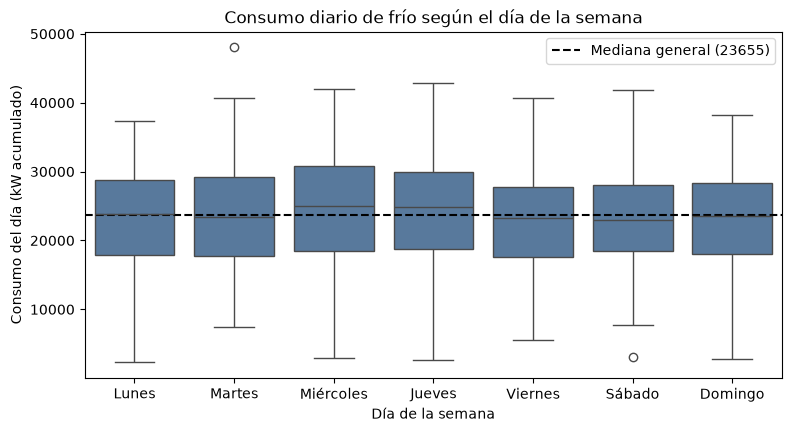

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=analisis, x="dia_semana", y="consumo_dia", order=dias_semana, color="#4C78A8", ax=ax)
ax.axhline(analisis["consumo_dia"].median(), color="black", linestyle="--", label=f"Mediana general ({(analisis["consumo_dia"].median()):.0f})")
ax.set_xlabel("Día de la semana")
ax.set_ylabel("Consumo del día (kW acumulado)")
ax.set_title("Consumo diario de frío según el día de la semana")
ax.legend()
plt.show()


**Paso 5: medir el efecto.** A simple vista el efecto no parece significativo. Pero para que dicha conclusión sea rigurosa, hay que medirlo. Se calculan cuatro medidas: la diferencia entre el mejor y el peor día (en kW y como porcentaje del promedio), qué porcentaje de toda la variación del consumo explica el día de la semana, y el p-valor de una prueba estadística (Kruskal-Wallis) que responde: si el día de la semana no influyera en nada, ¿qué tan probable sería ver diferencias tan grandes como estas solo por azar?


In [27]:
from scipy.stats import kruskal

grupos = [grupo["consumo_dia"].to_numpy() for _, grupo in analisis.groupby("dia_semana")]
estadistico, p_valor = kruskal(*grupos)

promedio_general = analisis["consumo_dia"].mean()
promedio_por_dia = analisis.groupby("dia_semana")["consumo_dia"].transform("mean")
variacion_entre_dias = ((promedio_por_dia - promedio_general) ** 2).sum()
variacion_total = ((analisis["consumo_dia"] - promedio_general) ** 2).sum()
porcentaje_explicado = 100 * variacion_entre_dias / variacion_total

diferencia = resumen_semana["Promedio"].max() - resumen_semana["Promedio"].min()

medidas = pd.DataFrame({"Valor": {
    "Diferencia entre el día más alto y el más bajo (kW)": diferencia,
    "Esa diferencia, como % del promedio general": 100 * diferencia / promedio_general,
    "% de la variación total explicado por el día de la semana": porcentaje_explicado,
    "p-valor de la prueba de Kruskal-Wallis": p_valor,
}})
display(tabla_simple(medidas, precision=2))


,Valor
Diferencia entre el día más alto y el más bajo (kW),1692.72
"Esa diferencia, como % del promedio general",7.19
% de la variación total explicado por el día de la semana,0.60
p-valor de la prueba de Kruskal-Wallis,0.40


**Conclusión del efecto del día de la semana.** No se detecta un efecto. El día más alto (miércoles, 24.585 kW de promedio) y el más bajo (lunes, 22.892 kW) difieren en 1.693 kW, un 7,19 % del promedio general, pero esa diferencia es compatible con el azar. La prueba de Kruskal-Wallis da p = 0,40 (muy por encima de 0,05. No hay evidencia suficiente para afirmar con un 95% de confianza que el día tenga un efecto significativo sobre el consumo) y el día de la semana explica solo el 0,60 % de la variación total del consumo. Los fines de semana no consumen menos que los días hábiles. Por lo tanto, **el día de la semana se descarta como variable del modelo**.

**Salvedad.** El día de la semana se calculó con las fechas rotuladas, que pueden estar corridas algunos días (ADR 0002). Si lo estuvieran, un efecto semanal real quedaría borroso y no lo veríamos. Así, nuestro análisis anterior se reformularía como: "con las fechas tal como vienen rotuladas, no hay evidencia de efecto semanal". 


## 15. Evolución temporal del consumo

**Intentamos responder** ¿cómo cambia el consumo de frío a lo largo del tiempo? ¿Hay una tendencia, una estacionalidad (subidas y bajadas que se repiten) o saltos raros?

**Paso 1: la serie completa.** Se dibuja el consumo de cada día, en el orden de las filas de `diario` y no por fecha del calendario, porque las fechas rotuladas se repiten y tienen desfasajes (ADR 0002). La línea oscura es el promedio móvil de 30 días: para cada día, unos 15 días a cada lado. Suaviza el ruido diario y deja ver la tendencia.


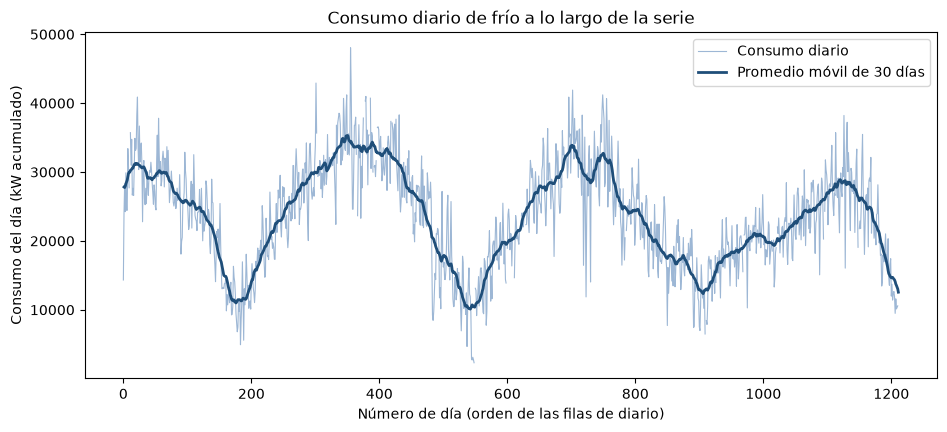

In [28]:
tendencia = diario["consumo_dia"].rolling(30, min_periods=15, center=True).mean()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(diario.index, diario["consumo_dia"], color="#9DB7D5", linewidth=0.8, label="Consumo diario")
ax.plot(diario.index, tendencia, color="#1F4E79", linewidth=2, label="Promedio móvil de 30 días")
ax.set_xlabel("Número de día (orden de las filas de diario)")
ax.set_ylabel("Consumo del día (kW acumulado)")
ax.set_title("Consumo diario de frío a lo largo de la serie")
ax.legend()
plt.show()


**Paso 2: el consumo según el mes.** Se agrupan los días válidos por el mes de su fecha rotulada y se calcula, para cada mes, cuántos días tiene, su promedio y su mediana, y se dibuja un boxplot por mes. Si el consumo sube en verano, tendría que verse acá. A diferencia del día de la semana, un corrimiento de unos pocos días en las fechas afecta poco al mes, así que esta agrupación es bastante más confiable.


,Días,Promedio,Mediana
Mes,,,
Ene,91,13733,14626
Feb,91,19594,19475
Mar,85,23141,22408
Abr,90,25517,25371
May,90,27680,28749
Jun,93,30322,31034
Jul,117,30651,30534
Ago,109,28930,29638
Sep,124,26449,26340


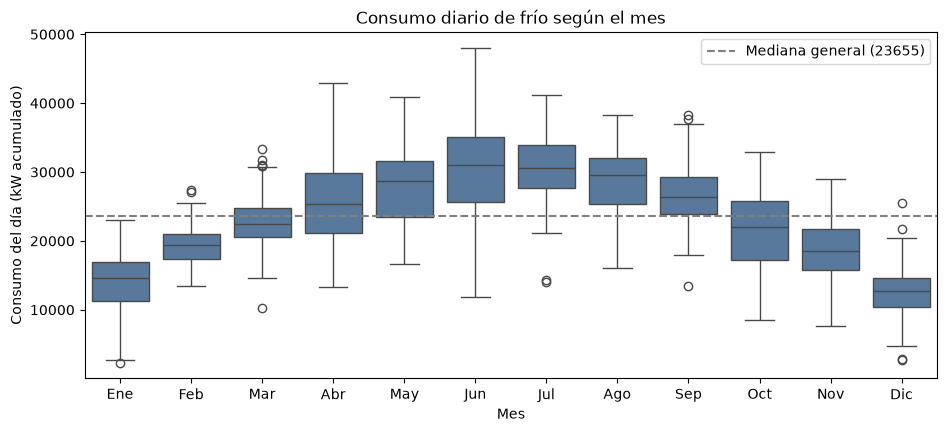

In [29]:
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

por_mes = diario.loc[diario["valido"], ["DIA", "consumo_dia"]].copy()
por_mes["mes"] = por_mes["DIA"].dt.month.map(dict(enumerate(meses, start=1)))

resumen_mes = por_mes.groupby("mes")["consumo_dia"].agg(["count", "mean", "median"]).reindex(meses)
resumen_mes.columns = ["Días", "Promedio", "Mediana"]
resumen_mes.index.name = "Mes"
display(tabla_simple(resumen_mes, precision=0))

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=por_mes, x="mes", y="consumo_dia", order=meses, color="#4C78A8", ax=ax)
mediana = por_mes["consumo_dia"].median()
ax.axhline(mediana, color="gray", linestyle="--", label=f"Mediana general ({mediana:.0f})")
ax.set_xlabel("Mes")
ax.set_ylabel("Consumo del día (kW acumulado)")
ax.set_title("Consumo diario de frío según el mes")
ax.legend()
plt.show()


**Paso 3: medir el efecto del mes.** Se usa la función `medir_efecto_por_grupo`, que calcula las mismas cuatro medidas que para el día de la semana: la diferencia entre el mes más alto y el más bajo, esa diferencia como porcentaje del promedio general, el porcentaje de la variación total que explica el mes y el p-valor de Kruskal-Wallis.


In [30]:
from auxiliar_functions import medir_efecto_por_grupo

_, medidas_mes = medir_efecto_por_grupo(por_mes, "mes", "consumo_dia", orden=meses)
display(tabla_simple(medidas_mes, precision=2))


,Valor
Diferencia entre el grupo más alto y el más bajo,17972.12
"Esa diferencia, como % del promedio general",76.30
% de la variación total explicado por los grupos,58.78
p-valor de la prueba de Kruskal-Wallis,0.00


**Paso 4: un año por línea.** Se calcula el promedio de cada mes en cada año (2020 a 2023) y se dibuja una línea por año. Si los años tienen la misma forma, las líneas se superponen. Si una se separa, ese año fue distinto. Este análisis es motivado al ver que el final de la serie (octubre 2023) cae significativamente, mientras que en los box plots mensuales octubre no está tan bajo.


Consumo promedio por mes por año:


anio,2020,2021,2022,2023
mes,,,,
Ene,nan,12905,12737,15585
Feb,nan,20305,19706,18746
Mar,nan,25544,22906,20934
Abr,nan,28967,27802,19506
May,nan,30384,30086,22570
Jun,nan,35183,31166,24617
Jul,30306,32917,31814,27828
Ago,29121,33175,25825,27790
Sep,28452,29107,24475,23760


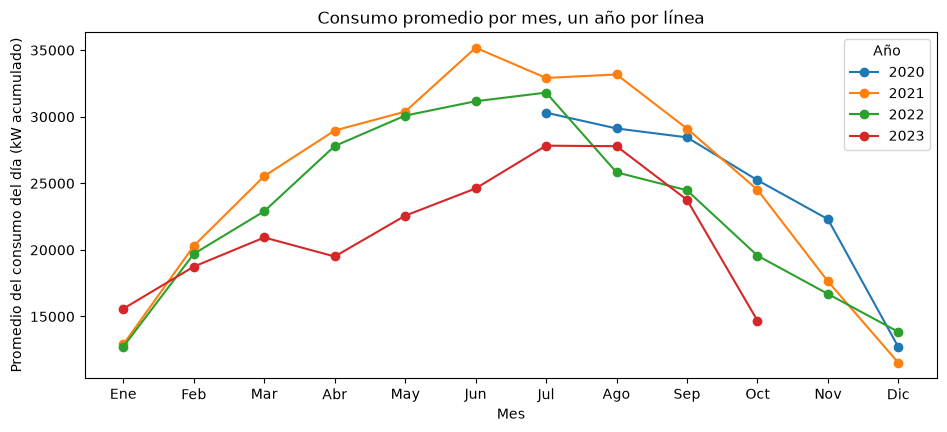

In [31]:
por_mes["anio"] = por_mes["DIA"].dt.year

promedio_mes_anio = por_mes.pivot_table(index="mes", columns="anio", values="consumo_dia", aggfunc="mean").reindex(meses)
print("Consumo promedio por mes por año:")
display(tabla_simple(promedio_mes_anio, precision=0))

fig, ax = plt.subplots(figsize=(11, 4.5))
for anio in promedio_mes_anio.columns:
    ax.plot(promedio_mes_anio.index, promedio_mes_anio[anio], marker="o", label=str(anio))
ax.set_xlabel("Mes")
ax.set_ylabel("Promedio del consumo del día (kW acumulado)")
ax.set_title("Consumo promedio por mes, un año por línea")
ax.legend(title="Año")
plt.show()


**Paso 5: medir la baja entre años.** Para quitar el efecto de la estación se calcula, para cada día, un índice del mes: su consumo dividido por el promedio de ese mes en toda la serie. Después se comparan los años con ese índice.


In [32]:
por_mes["indice_mes"] = por_mes["consumo_dia"] / por_mes.groupby("mes")["consumo_dia"].transform("mean")

resumen_anio, medidas_anio = medir_efecto_por_grupo(por_mes, "anio", "indice_mes")
display(tabla_simple(resumen_anio, precision=3))
display(tabla_simple(medidas_anio, precision=3))


,Días,Promedio,Mediana
anio,,,
2020,180,1.075,1.059
2021,357,1.064,1.074
2022,356,0.991,0.986
2023,294,0.887,0.874


,Valor
Diferencia entre el grupo más alto y el más bajo,0.187
"Esa diferencia, como % del promedio general",18.732
% de la variación total explicado por los grupos,11.164
p-valor de la prueba de Kruskal-Wallis,0.000


**Paso 6: autocorrelación.** Se mide cuánto se parece el consumo de un día al de 1, 2, 7 y 30 días antes. La medida es la correlación de Parson entre la serie y esa misma serie corrida hacia atrás. "Días antes" se cuenta en filas de `diario` (cada una es un bloque), consistente con el ADR 0002. Los pares en que alguno de los dos días es inválido se ignoran.


In [33]:
consumo = diario["consumo_dia"]
rezagos = [1, 2, 7, 30]

autocorrelaciones = pd.DataFrame({"Correlación": {f"Con {r} día(s) antes": consumo.autocorr(lag=r) for r in rezagos}})
display(tabla_simple(autocorrelaciones, precision=3))


,Correlación
Con 1 día(s) antes,0.854
Con 2 día(s) antes,0.761
Con 7 día(s) antes,0.750
Con 30 día(s) antes,0.580


**Conclusión del análisis temporal.**

- **Estacionalidad mensual muy marcada.** El consumo de frío sube de enero (13.733 kW de promedio) a julio (30.651 kW) y baja hasta diciembre (12.678 kW). El pico va de junio a agosto, coherente con el verano del hemisferio norte. La diferencia entre el mes más alto y el más bajo es de 17.972 kW (76 % del promedio general) y el mes explica el **58,8 %** de la variación del consumo (Kruskal-Wallis, p < 0,001). Como el mes se calcula con la fecha rotulada, un posible corrimiento de unos pocos días lo afecta muy poco.
- **Nivel decreciente entre años.** Comparando cada día con el promedio de su mes, el índice promedio es 1,075 (2020), 1,064 (2021), 0,991 (2022) y 0,887 (2023): una baja de unos 17 % entre 2021 y 2023. El año explica el 11,2 % de la variación del índice. No parece un efecto del cambio de archivo, porque los Excel que se solapan coinciden salvo en 5 días (ADR 0003). La causa no está identificada.
- **Mucha inercia día a día.** La correlación del consumo con el del día anterior es 0,854; con el de 2 días antes, 0,761; con el de 7 días, 0,750; con el de 30 días, 0,580. El rezago de 7 días no destaca, en línea con haber descartado el día de la semana como variable influyente.

**Salvedades.** (1) Hay solo unos tres ciclos anuales, así que la baja entre años no debería extrapolarse con confianza. (2) Por la autocorrelación, los p-valores son optimistas; las conclusiones se apoyan en las diferencias y en el porcentaje explicado. (3) Las etiquetas de fecha pueden estar corridas unos días (ADR 0002).

**Para las fases siguientes (hipótesis).** El mes, o variables que capturen la estación, son candidatos fuertes. Las variables de consumo de días anteriores aportan mucha información y se ajustan solas al nivel del momento.


## 16. Valores atípicos y registros inválidos

**Pregunta:** ¿hay días con consumos imposibles o sospechosos que el corte provisorio de 100.000 no detecta? La consigna del proyecto pide detectar tres tipos de registros inválidos: días incompletos, valores del orden de los millones y días en que el totalizador no se reinició a medianoche. Los pasos 1 a 7 exploran los datos para encontrar las fallas; el paso 8 muestra la regla definitiva (ADR 0005), que ya aplica `construir_diario`.


**Preparación.** Para explorar se usa el consumo de cierre de los días que pasan solo los filtros del ADR 0004 (llegan a las 23:59 y no son de millones), así se ven las fallas que detecta la regla del ADR 0005. `exploracion` es una copia de `diario` con ese consumo y con el cierre del día anterior y del siguiente. Las columnas `lectura_inicial`, `mayor_incremento`, `menor_incremento` y `tipo_falla` ya vienen en `diario`.

In [34]:
exploracion = diario.copy()
exploracion["consumo_dia"] = exploracion[COLUMNA_CONSUMO].where(exploracion["completo"] & exploracion["plausible"])
exploracion["cierre_dia_anterior"] = exploracion["consumo_dia"].shift(1)
exploracion["cierre_dia_siguiente"] = exploracion["consumo_dia"].shift(-1)

**Paso 1: los extremos.** Los 10 consumos más altos y los 10 más bajos entre los días que llegan a las 23:59 y no son de millones (todavía sin aplicar la regla nueva), con su posición en la serie (`Fila`), su fecha y de qué archivo salen.

In [35]:
columnas_extremos = ["DIA", "bloque", "archivo", "filas", "consumo_dia"]
altos = formatear_fechas(exploracion.nlargest(10, "consumo_dia")[columnas_extremos])
bajos = formatear_fechas(exploracion.nsmallest(10, "consumo_dia")[columnas_extremos])
altos.index.name = bajos.index.name = "Fila"

mostrar_lado_a_lado_simple([("Los 10 consumos más altos", altos), ("Los 10 más bajos", bajos)], precision=0)


,DIA,bloque,archivo,filas,consumo_dia
Fila,,,,,
396,2021-08-01,0,2021-2023,25,56128
385,2021-07-21,0,2021-2023,25,54681
355,2021-06-22,0,2020-2022,25,48046
376,2021-07-12,0,2021-2023,25,46001
301,2021-04-29,0,2020-2022,25,42919
419,2021-08-24,0,2021-2023,25,42604
356,2021-06-23,0,2020-2022,25,42005
702,2022-06-04,0,2021-2023,25,41901
749,2022-07-20,0,2022-2023,25,41206


**Paso 2: Reinicio del totalizador a medianoche** En un día normal la lectura de las 00:00 es cercana a cero. Si el totalizador no se reinició, esa primera lectura queda cerca del cierre del día anterior y el cierre del día suma dos jornadas. Se toma la primera lectura de cada bloque, se la compara con el cierre del día anterior y se miran los 10 días con la lectura inicial más alta y los 10 de mayor consumo.


In [36]:
columnas_inicio = ["DIA", "lectura_inicial", "consumo_dia", "cierre_dia_anterior"]
mayor_inicio = formatear_fechas(exploracion.nlargest(10, "lectura_inicial")[columnas_inicio])
consumo_alto = formatear_fechas(exploracion.nlargest(10, "consumo_dia")[columnas_inicio])
mayor_inicio.index.name = consumo_alto.index.name = "Fila"

resumen_inicial = exploracion["lectura_inicial"].describe(percentiles=[0.5, 0.95, 0.99]).to_frame("lectura_inicial")
print("Característica principales de las mediciones a las 00:00 hs de la serie cronológica")
display(tabla_simple(resumen_inicial, precision=0))
mostrar_lado_a_lado_simple([("Las 10 mayores lecturas a las 00:00", mayor_inicio), ("Los 10 de mayor consumo", consumo_alto)], precision=0)

Característica principales de las mediciones a las 00:00 hs de la serie cronológica


,lectura_inicial
count,1212
mean,42
std,1034
min,0
50%,0
95%,0
99%,0
max,29113


,DIA,lectura_inicial,consumo_dia,cierre_dia_anterior
Fila,,,,
10,2020-07-11,29113,29046,27721
1095,2023-07-01,21200,32067,20274
365,2021-07-01,787,16411,32571
581,2022-02-05,7,20203,17094
0,2020-07-01,0,14325,nan
1,2020-07-02,0,23954,14325
2,2020-07-03,0,28268,23954
3,2020-07-04,0,24246,28268
4,2020-07-05,0,29885,24246


**Paso 3: Vemos si el totalizador funciona correctamente** El totalizador es acumulativo: dentro de un día tiene que subir de a unos 1.000 a 1.500 kW por hora y nunca bajar. Para cada día se calcula el **mayor incremento** entre dos lecturas seguidas y el **menor incremento** (la diferencia más baja; si es negativa, el contador bajó). Un salto de miles en una sola hora, o un retroceso, indican un problema de medición.


In [37]:
columnas_saltos = ["DIA", "archivo", "consumo_dia", "mayor_incremento", "menor_incremento"]
mayores_saltos = formatear_fechas(exploracion.nlargest(10, "mayor_incremento")[columnas_saltos])
mayores_retrocesos = formatear_fechas(exploracion.nsmallest(10, "menor_incremento")[columnas_saltos])
mayores_saltos.index.name = mayores_retrocesos.index.name = "Fila"

resumen_saltos = exploracion[["mayor_incremento", "menor_incremento"]].describe(percentiles=[0.5, 0.95, 0.99])
print("Resumen de los incrementos entre lecturas seguidas, sobre todos los días")
display(tabla_simple(resumen_saltos, precision=0))
mostrar_lado_a_lado_simple([("Los 10 mayores saltos", mayores_saltos), ("Los 10 menores retrocesos", mayores_retrocesos)], precision=0)

Resumen de los incrementos entre lecturas seguidas, sobre todos los días


,mayor_incremento,menor_incremento
count,1212,1212
mean,54078014798033,-54078014791433
std,1330692367486730,1330692367486922
min,227,-32771277123571584
50%,1347,603
95%,2212,1023
99%,11511,1182
max,32771277123572972,1432


,DIA,archivo,consumo_dia,mayor_incremento,menor_incremento
Fila,,,,,
211,2021-01-31,2020-2022,16218,32771277123572972,-32771277123571584
294,2021-04-22,2020-2022,27116,32771276800000952,-32771276799998576
303,2021-04-30,2020-2022,nan,5541542,880
345,2021-06-12,2020-2022,37992,4111695,-4108137
276,2021-04-04,2020-2022,24715,33521,-31131
69,2020-09-11,2020-2022,29293,31782,-28674
1053,2023-05-20,2022-2023,26964,30256,-27999
260,2021-03-18,2020-2022,24261,29166,-27138
261,2021-03-19,2020-2022,23964,27976,-26003


**Paso 4: cuántos días tienen problemas y cuáles.** Se cuenta cuántos días superan distintos umbrales de incremento, cuántos tienen un contador que bajó y cuántos arrancan distinto de cero. Después se lista, con fecha y el archivo, cada día que cae en alguno de esos casos. `mayor_incremento` es el mayor aumento entre dos lecturas seguidas del día y `menor_incremento` el menor (negativo si el contador bajó).


In [38]:
umbrales = [3_000, 5_000, 10_000]
conteo = pd.DataFrame({"Días": {
    **{f"Incremento mayor a {u:,}".replace(",", "."): int((exploracion["mayor_incremento"] > u).sum()) for u in umbrales},
    "El contador bajó en algún momento (menor_incremento < 0)": int((exploracion["menor_incremento"] < 0).sum()),
    "Arranca distinto de cero (más de 100 a las 00:00)": int((exploracion["lectura_inicial"] > 100).sum()),
}})

hay_problema = (exploracion["mayor_incremento"] > 5_000) | (exploracion["menor_incremento"] < 0) | (exploracion["lectura_inicial"] > 100)
columnas_problema = ["DIA", "archivo", "filas", "lectura_inicial", "mayor_incremento", "menor_incremento", "consumo_dia"]
problemas = formatear_fechas(exploracion.loc[hay_problema, columnas_problema])
problemas.index.name = "Fila"

mostrar_lado_a_lado_simple([("Cuántos días cumplen cada criterio", conteo)], precision=0)
mostrar_lado_a_lado_simple([(f"Días con alguna falla posible ({len(problemas)} días)", problemas)], precision=0)


,Días
Incremento mayor a 3.000,46
Incremento mayor a 5.000,33
Incremento mayor a 10.000,15
El contador bajó en algún momento (menor_incremento < 0),23
Arranca distinto de cero (más de 100 a las 00:00),3


,DIA,archivo,filas,lectura_inicial,mayor_incremento,menor_incremento,consumo_dia
Fila,,,,,,,
10,2020-07-11,2020-2022,25,29113,1553,-29113,29046
69,2020-09-11,2020-2022,25,0,31782,-28674,29293
183,2021-01-03,2020-2022,25,0,596,-10,4925
201,2021-01-21,2020-2022,25,0,1005,-13,16699
211,2021-01-31,2020-2022,25,0,32771277123572972,-32771277123571584,16218
260,2021-03-18,2020-2022,25,0,29166,-27138,24261
261,2021-03-19,2020-2022,25,0,27976,-26003,23964
276,2021-04-04,2020-2022,25,0,33521,-31131,24715
293,2021-04-21,2020-2022,25,0,8139,-5405,31212


**Paso 5: los casos clave, hora por hora.** Se comparan las 25 lecturas de cuatro días: un día normal de referencia (fila 395), el de mayor consumo (fila 396), el que arranca en 29.113 (fila 10) y un pico que revierte (fila 302). Primero las lecturas, después el incremento de cada una respecto de la anterior, y un gráfico con las cuatro curvas.


,Fila 395 (día normal),Fila 396 (el mayor consumo),Fila 10 (arranca en 29.113),Fila 302 (pico que revierte)
HORA,,,,
00:00:00,0,0,29113,0
01:00:00,1763,1270,0,1539
02:00:00,3396,2576,1544,3120
03:00:00,4746,3317,3097,4197
04:00:00,6411,4008,4415,5583
05:00:00,7734,5126,5859,17101
06:00:00,9218,6278,7375,8655
07:00:00,10650,6803,8795,10347
08:00:00,11919,8054,9965,11885


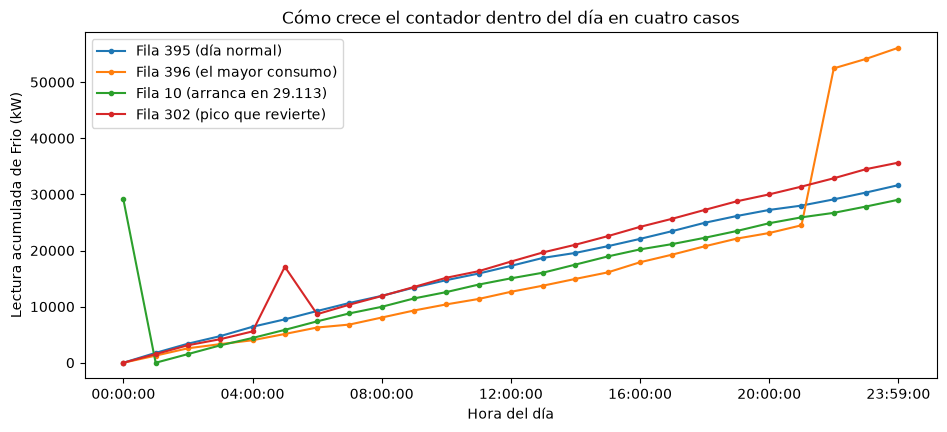

In [39]:
def lecturas_del_dia(fila):
    """Las lecturas horarias de Frio del día `fila` de exploracion, indexadas por hora.

    Busca el bloque de ese día entre los cierres de su archivo (la fila i de `cierres`
    es el bloque i) y devuelve sus lecturas originales de `tablas`.
    """
    dia = exploracion.loc[fila]
    cierre = cierres[dia["archivo"]]
    numero = cierre.index[(cierre["DIA"] == dia["DIA"]) & (cierre["bloque"] == dia["bloque"])][0]
    tabla = tablas[dia["archivo"]]
    return tabla.loc[numerar_bloques(tabla) == numero].set_index("HORA")[COLUMNA_CONSUMO]


casos = {
    "Fila 395 (día normal)": 395,
    "Fila 396 (el mayor consumo)": 396,
    "Fila 10 (arranca en 29.113)": 10,
    "Fila 302 (pico que revierte)": 302,
}
lecturas = pd.DataFrame({nombre: lecturas_del_dia(fila) for nombre, fila in casos.items()})

mostrar_lado_a_lado_simple([
    ("Lectura de Frio, hora por hora", lecturas),
    ("Incremento respecto de la lectura anterior", lecturas.diff()),
], precision=0)

fig, ax = plt.subplots(figsize=(11, 4.5))
for nombre in lecturas.columns:
    ax.plot(lecturas.index, lecturas[nombre], marker="o", markersize=3, label=nombre)
ax.set_xticks(lecturas.index[::4])
ax.set_xlabel("Hora del día")
ax.set_ylabel("Lectura acumulada de Frio (kW)")
ax.set_title("Cómo crece el contador dentro del día en cuatro casos")
ax.legend()
plt.show()


**Paso 6: clasificar los días con falla.** Mirando las lecturas hora por hora aparecen tres tipos. Un **salto sin corregir** (fila 396): el contador salta y se queda arriba, así que el cierre queda inflado. Un **salto corregido** (fila 302): una lectura sale muy alta y la siguiente vuelve a la normalidad, así que el cierre es correcto. Un **reinicio tardío** (fila 10): el contador arrastra el valor del día anterior y baja a cero horas después de la medianoche. Se distinguen sumando el mayor y el menor incremento del día: en un pico la subida y la bajada se compensan (suma chica) y en un escalón no (suma grande). La clasificación la hace `clasificar_fallas` en `src/auxiliar_functions.py`, y el resultado queda en la columna `tipo_falla` de `diario`.


In [40]:
conteo_tipos = exploracion["tipo_falla"].value_counts().rename("Días").to_frame()
con_falla = exploracion[exploracion["tipo_falla"] != "Sin falla grave"].sort_values(["tipo_falla", "DIA"])
columnas_tipo = ["DIA", "tipo_falla", "consumo_dia", "cierre_dia_anterior", "cierre_dia_siguiente"]
detalle = formatear_fechas(con_falla[columnas_tipo])
detalle.index.name = "Fila"

mostrar_lado_a_lado_simple([("Cuántos días hay de cada tipo", conteo_tipos)], precision=0)
mostrar_lado_a_lado_simple([(f"Días con falla grave ({len(detalle)} días), con el cierre de los días vecinos", detalle)], precision=0)

,Días
tipo_falla,
Sin falla grave,1178
Salto corregido,17
Salto no corregido,16
Reinicio tardío,1


,DIA,tipo_falla,consumo_dia,cierre_dia_anterior,cierre_dia_siguiente
Fila,,,,,
10,2020-07-11,Reinicio tardío,29046,27721,35721
69,2020-09-11,Salto corregido,29293,33680,33150
211,2021-01-31,Salto corregido,16218,18962,18601
260,2021-03-18,Salto corregido,24261,26464,23964
261,2021-03-19,Salto corregido,23964,24261,22902
276,2021-04-04,Salto corregido,24715,22380,24614
293,2021-04-21,Salto corregido,31212,34174,27116
294,2021-04-22,Salto corregido,27116,31212,26058
297,2021-04-25,Salto corregido,27720,27044,26489


**Paso 7: los saltos no corregidos.** Son los días en que el contador saltó y no volvió a bajar, así que el cierre queda inflado. Para cada uno se muestra su cierre, el de los días vecinos y cuánto por encima (en %) está del promedio de esos dos vecinos. Si el porcentaje es muy alto, el cierre no es un consumo real. Ojo: el porcentaje es una guía, no una prueba. Cuando los vecinos son días de cierre de planta (fiestas de fin de año) o también fallan, el porcentaje sale inflado o distorsionado.


In [41]:
vecinos = exploracion[["cierre_dia_anterior", "cierre_dia_siguiente"]].mean(axis=1)
exploracion["pct_sobre_vecinos"] = 100 * (exploracion["consumo_dia"] / vecinos - 1)

columnas_no_corregidos = ["DIA", "archivo", "mayor_incremento", "consumo_dia", "cierre_dia_anterior", "cierre_dia_siguiente", "pct_sobre_vecinos"]
no_corregidos = formatear_fechas(exploracion.loc[exploracion["tipo_falla"] == "Salto no corregido", columnas_no_corregidos])
no_corregidos.index.name = "Fila"

mostrar_lado_a_lado_simple([(f"Días con salto no corregido ({len(no_corregidos)} días)", no_corregidos)], precision=0)


,DIA,archivo,mayor_incremento,consumo_dia,cierre_dia_anterior,cierre_dia_siguiente,pct_sobre_vecinos
Fila,,,,,,,
303,2021-04-30,2020-2022,5541542,nan,35657,29361,nan
376,2021-07-12,2021-2023,6597,46001,37846,nan,22
385,2021-07-21,2021-2023,17689,54681,35377,40720,44
391,2021-07-27,2021-2023,14751,41148,29997,30764,35
396,2021-08-01,2021-2023,27963,56128,31644,36469,65
419,2021-08-24,2021-2023,11161,42604,37352,37122,14
549,2022-01-04,2021-2023,8215,16176,2310,13120,110
599,2022-02-23,2021-2023,5199,29813,13886,18939,82
610,2022-03-03,2021-2023,5039,18835,nan,14659,28


**Paso 8: la regla definitiva (ADR 0005).** Con lo que mostraron los pasos anteriores, `construir_diario` marca inválido, además de lo del ADR 0004, a todo día con un salto no corregido, un reinicio tardío o una lectura inicial mayor a 100 kW (`clasificar_fallas` y `construir_diario` en `src/auxiliar_functions.py`). Los saltos corregidos siguen siendo válidos, porque su cierre es confiable. El conteo por motivo está en la sección 12 (tabla "Resultado de la regla de validez"). Acá se listan los días inválidos y se comprueba el criterio de la consigna sobre la cantidad de lecturas por día.

In [42]:
columnas_invalidos = ["DIA", "bloque", "archivo", "filas", "lectura_inicial", "mayor_incremento", "menor_incremento", "tipo_falla", COLUMNA_CONSUMO]
invalidos_final = formatear_fechas(diario.loc[~diario["valido"], columnas_invalidos])
invalidos_final.index.name = "Fila"
mostrar_lado_a_lado_simple([(f"Los {len(invalidos_final)} días inválidos con la regla definitiva", invalidos_final)], precision=0)

,DIA,bloque,archivo,filas,lectura_inicial,mayor_incremento,menor_incremento,tipo_falla,Frio (Kw)
Fila,,,,,,,,,
10,2020-07-11,0,2020-2022,25,29113,1553,-29113,Reinicio tardío,29046
303,2021-04-30,1,2020-2022,25,0,5541542,880,Salto no corregido,5572801
365,2021-07-01,0,2021-2023,23,787,852,591,Sin falla grave,16411
376,2021-07-12,0,2021-2023,25,0,6597,1072,Salto no corregido,46001
377,2021-07-13,0,2021-2023,23,0,2260,444,Sin falla grave,33704
385,2021-07-21,0,2021-2023,25,0,17689,1140,Salto no corregido,54681
391,2021-07-27,0,2021-2023,25,0,14751,-8868,Salto no corregido,41148
396,2021-08-01,0,2021-2023,25,0,27963,525,Salto no corregido,56128
419,2021-08-24,0,2021-2023,25,0,11161,725,Salto no corregido,42604


In [43]:
pocas_lecturas = formatear_fechas(diario.loc[diario["valido"] & ((diario["filas"] < 24) | (diario["filas"] > 25)), ["DIA", "bloque", "archivo", "filas"]])
pocas_lecturas.index.name = "Fila"
mostrar_lado_a_lado_simple([(f"Días válidos con menos de 24 o más de 25 lecturas ({len(pocas_lecturas)} días)", pocas_lecturas)], precision=0)

,DIA,bloque,archivo,filas
Fila,,,,
364,2021-06-30,1,2020-2022,26
485,2021-11-01,0,2021-2023,23
729,2022-06-30,1,2021-2023,26
1094,2023-06-30,1,2022-2023,26


**Conclusión de los atípicos y los registros inválidos.**

- **Tres tipos de falla del contador.** Un *salto no corregido* (el contador salta de golpe y se queda arriba, así que el cierre queda inflado; por ejemplo el 01/08/2021, 56.128 kW, con un aumento de 27.963 en una sola hora), un *salto corregido* (una lectura errónea que se corrige sola antes de las 23:59, con el cierre confiable) y un *reinicio tardío* (el contador arranca con el valor del día anterior y baja a cero horas después de la medianoche).
- **Regla definitiva (ADR 0005).** Además de los criterios del ADR 0004, se marca inválido un día con un salto no corregido, un reinicio tardío o una lectura inicial mayor a 100 kW. No se imputa. Resultado: **1.187 días válidos y 25 inválidos**, con 1.186 filas con objetivo. Los 17 días con salto corregido siguen siendo válidos.
- **No se usa un rango fijo.** Con la regla, los días válidos llegan hasta 48.046 kW. El rango "0 a 35.000" de la documentación del dataset habría descartado días reales.
- **Las conclusiones anteriores no cambian.** El día de la semana explica el 0,60 % de la variación, el mes el 58,8 % y el año el 11,2 %.
- **Las fallas se concentran en el tiempo.** 11 de los 16 saltos no corregidos caen en julio-agosto de 2021 (5) y en enero-marzo de 2022 (6). La causa no está identificada.
- **Lecturas por día.** Entre los días válidos hay uno con 23 lecturas (01/11/2021) y tres con 26 (el 30/06 de 2021, 2022 y 2023). Se mantienen: llegan a las 23:59 y arrancan en cero.

**Salvedades.** (1) El umbral de 5.000 kW por hora es un criterio, no una verdad. (2) La regla es conservadora: algunos días invalidados tenían un cierre coherente con sus vecinos. (3) Solo se mira la columna `Frio (Kw)`.

## 17. Baselines

**Pregunta:** ¿qué error tienen las dos predicciones más simples posibles? El modelo tiene que mejorarlas (criterio de la consigna).

- **Persistencia:** el consumo de mañana será igual al de hoy.
- **Media móvil:** el consumo de mañana será el promedio de los últimos 7 días (hoy incluido). Los días inválidos no entran en el promedio, pero se piden al menos 4 días válidos en la ventana.

El error se mide con el **MAE** (error absoluto medio, en kW). Los dos baselines se evalúan sobre exactamente las mismas filas: las que tienen objetivo y las dos predicciones. Las demás no se evalúan ni se completan (ADR 0004). Este MAE es sobre toda la serie y es preliminar: el oficial se calcula sobre el conjunto de prueba del modelo.


In [48]:
from auxiliar_functions import MINIMO_DIAS_MEDIA_MOVIL, VENTANA_MEDIA_MOVIL, calcular_baselines, evaluar_baselines

baselines = calcular_baselines(diario)
resumen_baselines, evaluadas = evaluar_baselines(diario)

hay_objetivo = diario["objetivo"].notna()
filas = pd.DataFrame({"Filas": {
    "Filas de la tabla diaria": len(diario),
    "Sin objetivo (su mañana es inválido o no existe)": int((~hay_objetivo).sum()),
    "Con objetivo": int(hay_objetivo.sum()),
    "Sin persistencia (el día de hoy es inválido)": int((hay_objetivo & baselines["persistencia"].isna()).sum()),
    f"Sin media móvil (menos de {MINIMO_DIAS_MEDIA_MOVIL} días válidos en los últimos {VENTANA_MEDIA_MOVIL})": int((hay_objetivo & baselines["media_movil"].isna()).sum()),
    "Filas evaluadas (con objetivo y las dos predicciones)": len(evaluadas),
}})

muestra = formatear_fechas(diario[["DIA", "consumo_dia", "objetivo"]].join(baselines[["media_movil"]]).head(8))
muestra = muestra.rename(columns={"consumo_dia": "consumo de hoy", "media_movil": "media móvil"})

mostrar_lado_a_lado_simple([("Qué filas se pueden evaluar", filas)], precision=0)
mostrar_lado_a_lado_simple([("Las primeras filas: predicción de cada baseline y el objetivo real", muestra)], precision=0)
mostrar_lado_a_lado_simple([("Error de los dos baselines (MAE) sobre las mismas filas", resumen_baselines)], precision=0)


,Filas
Filas de la tabla diaria,1212
Sin objetivo (su mañana es inválido o no existe),26
Con objetivo,1186
Sin persistencia (el día de hoy es inválido),21
Sin media móvil (menos de 4 días válidos en los últimos 7),3
Filas evaluadas (con objetivo y las dos predicciones),1162


,DIA,consumo de hoy,objetivo,media móvil
0,2020-07-01,14325,23954,nan
1,2020-07-02,23954,28268,nan
2,2020-07-03,28268,24246,nan
3,2020-07-04,24246,29885,22698
4,2020-07-05,29885,24449,24136
5,2020-07-06,24449,24435,24188
6,2020-07-07,24435,33401,24223
7,2020-07-08,33401,30921,26948


,MAE (kW),Filas evaluadas
Consumo de hoy,3125,1162
Media móvil de 7 días,3141,1162


## 18. Alineación de las demás hojas con `Consolidado EE`

Para sumar variables de otras hojas hay que saber si tienen las mismas fechas y horas, fila por fila, que la hoja del objetivo.


In [ ]:
from auxiliar_functions import medir_alineacion
#Vemos si el resto de hojas del excel coninciden con "Consolidado EE" (la que contiene a la target feature).
#También se ve dónde se desalinean. 
filas = []
for nombre, libro in libros.items():
    referencia = pd.read_excel(libro, sheet_name="Consolidado EE")
    for hoja in libro.sheet_names:
        if hoja == "Consolidado EE":
            continue
        resultado = medir_alineacion(pd.read_excel(libro, sheet_name=hoja), referencia)
        filas.append({"Excel": nombre, "Hoja": hoja, **resultado})
alineacion = pd.DataFrame(filas)

orden_hojas = alineacion["Hoja"].unique()
porcentaje = alineacion.pivot(index="Hoja", columns="Excel", values="% que coincide").reindex(orden_hojas)
primera = alineacion.pivot(index="Hoja", columns="Excel", values="Primera fila distinta").reindex(orden_hojas)

mostrar_lado_a_lado_simple([("Porcentaje de filas que coinciden con Consolidado EE", porcentaje)], precision=2)
mostrar_lado_a_lado_simple([("Primera fila donde la hoja deja de coincidir (nan = coincide todo)", primera)], precision=0)


Excel,2020-2022,2021-2023,2022-2023
Hoja,,,
Consolidado KPI,58.57,99.99,99.96
Consolidado Produccion,58.57,99.99,99.96
Totalizadores Produccion,58.57,99.99,99.96
Totalizadores Energia,100.00,100.00,100.00
Consolidado Agua,99.85,99.84,100.00
Totalizadores Agua,99.85,99.84,100.00
Consolidado GasVapor,100.00,100.00,100.00
Totalizadores Gas y Vapor,100.00,100.00,100.00
Consolidado Aire,100.00,100.00,100.00


Excel,2020-2022,2021-2023,2022-2023
Hoja,,,
Consolidado KPI,1590,13131,4014
Consolidado Produccion,1590,13131,4014
Totalizadores Produccion,1590,13131,4014
Totalizadores Energia,nan,nan,nan
Consolidado Agua,9622,496,nan
Totalizadores Agua,9622,496,nan
Consolidado GasVapor,nan,nan,nan
Totalizadores Gas y Vapor,nan,nan,nan
Consolidado Aire,nan,nan,nan


In [ ]:
from auxiliar_functions import contexto_desfase

# Un caso por cada (Excel, fila) donde alguna hoja deja de coincidir; las hojas que fallan en la misma fila van juntas
casos = (alineacion.dropna(subset=["Primera fila distinta"])
         .groupby(["Excel", "Primera fila distinta"], sort=False)["Hoja"].apply(list)
         .reset_index())

for _, caso in casos.iterrows():
    nombre, fila, nombres_hojas = caso["Excel"], int(caso["Primera fila distinta"]), caso["Hoja"]
    libro = libros[nombre]
    referencia = pd.read_excel(libro, sheet_name="Consolidado EE")                  # la hoja del objetivo
    hojas = {h: pd.read_excel(libro, sheet_name=h) for h in nombres_hojas}          # todas las del grupo
    contexto = contexto_desfase(hojas, referencia, fila)
    mostrar_lado_a_lado_simple([(f"{nombre} | 1ra fila distinta: {fila}", contexto)], precision=0)


,Fila,Consolidado EE,Consolidado KPI,Consolidado Produccion,Totalizadores Produccion
0,1588,05/09/20 14:00:00,05/09/20 14:00:00,05/09/20 14:00:00,05/09/20 14:00:00
1,1589,05/09/20 15:00:00,05/09/20 15:00:00,05/09/20 15:00:00,05/09/20 15:00:00
2,1590,05/09/20 16:00:00,05/09/20 15:00:00,05/09/20 15:00:00,05/09/20 15:00:00
3,1591,05/09/20 17:00:00,05/09/20 17:00:00,05/09/20 17:00:00,05/09/20 17:00:00
4,1592,05/09/20 18:00:00,05/09/20 18:00:00,05/09/20 18:00:00,05/09/20 18:00:00


,Fila,Consolidado EE,Consolidado Agua,Totalizadores Agua
0,9620,20/07/21 23:00:00,20/07/21 23:00:00,20/07/21 23:00:00
1,9621,20/07/21 23:59:00,20/07/21 23:59:00,20/07/21 23:59:00
2,9622,21/07/21 00:00:00,21/07/21 1900-01-01 00:00:00,21/07/21 1900-01-01 00:00:00
3,9623,21/07/21 01:00:00,21/07/21 1900-01-01 01:00:00,21/07/21 1900-01-01 01:00:00
4,9624,21/07/21 02:00:00,21/07/21 1900-01-01 02:00:00,21/07/21 1900-01-01 02:00:00


,Fila,Consolidado EE,Totalizadores CO2
0,484,20/07/20 09:00:00,20/07/20 09:00:00
1,485,20/07/20 10:00:00,20/07/20 10:00:00
2,486,20/07/20 11:00:00,20/07/20 23:00:00
3,487,20/07/20 12:00:00,20/07/20 12:00:00
4,488,20/07/20 13:00:01,20/07/20 13:00:01


,Fila,Consolidado EE,Totalizadores Glicol
0,14516,04/02/22 22:00:00,04/02/22 22:00:00
1,14517,04/02/22 23:00:00,04/02/22 23:00:00
2,14518,04/02/22 23:59:00,05/02/22 11:00:00
3,14519,05/02/22 00:00:00,05/02/22 12:00:00
4,14520,05/02/22 01:00:00,05/02/22 13:00:00


,Fila,Consolidado EE,Auxiliar
0,22,01/07/20 22:00:00,01/07/20 22:00:00
1,23,01/07/20 23:00:00,01/07/20 23:00:00
2,24,01/07/20 23:59:00,02/07/20 23:59:00
3,25,02/07/20 00:00:00,02/07/20 00:00:00
4,26,02/07/20 01:00:00,02/07/20 01:00:00


,Fila,Consolidado EE,Consolidado KPI,Consolidado Produccion,Totalizadores Produccion,Auxiliar
0,13129,10/12/22 12:00:00,10/12/22 12:00:00,10/12/22 12:00:00,10/12/22 12:00:00,10/12/22 12:00:00
1,13130,10/12/22 13:00:00,10/12/22 13:00:00,10/12/22 13:00:00,10/12/22 13:00:00,10/12/22 13:00:00
2,13131,10/12/22 14:00:00,10/12/22 16:00:00,10/12/22 16:00:00,10/12/22 16:00:00,10/12/22 16:00:00
3,13132,10/12/22 15:00:00,10/12/22 15:00:00,10/12/22 15:00:00,10/12/22 15:00:00,10/12/22 15:00:00
4,13133,10/12/22 16:00:00,10/12/22 16:00:00,10/12/22 16:00:00,10/12/22 16:00:00,10/12/22 16:00:00


... (2 outputs left out)

,Fila,Consolidado EE,Seguimiento Dia
0,1852,16/09/21 06:00:01,16/09/21 06:00:01
1,1853,16/09/21 07:00:01,16/09/21 07:00:01
2,1854,16/09/21 08:00:00,16/09/21 09:00:00
3,1855,16/09/21 09:00:00,16/09/21 08:00:00
4,1856,16/09/21 10:00:00,16/09/21 10:00:00


,Fila,Consolidado EE,Consolidado KPI,Consolidado Produccion,Totalizadores Produccion,Auxiliar
0,4012,10/12/22 12:00:00,10/12/22 12:00:00,10/12/22 12:00:00,10/12/22 12:00:00,10/12/22 12:00:00
1,4013,10/12/22 13:00:00,10/12/22 13:00:00,10/12/22 13:00:00,10/12/22 13:00:00,10/12/22 13:00:00
2,4014,10/12/22 14:00:00,10/12/22 16:00:00,10/12/22 16:00:00,10/12/22 16:00:00,10/12/22 16:00:00
3,4015,10/12/22 15:00:00,10/12/22 15:00:00,10/12/22 15:00:00,10/12/22 15:00:00,10/12/22 15:00:00
4,4016,10/12/22 16:00:00,10/12/22 16:00:00,10/12/22 16:00:00,10/12/22 16:00:00,10/12/22 16:00:00


,Fila,Consolidado EE,Totalizadores CO2
0,5988,28/02/23 22:00:00,28/02/23 22:00:00
1,5989,28/02/23 23:00:00,28/02/23 23:00:00
2,5990,28/02/23 00:00:00,28/02/23 23:59:00
3,5991,28/02/23 01:00:00,28/02/23 00:00:00
4,5992,28/02/23 02:00:00,28/02/23 01:00:00


,Fila,Consolidado EE,Totalizadores Glicol
0,11065,19/09/23 14:00:00,19/09/23 14:00:00
1,11066,19/09/23 15:00:00,19/09/23 15:00:00
2,11067,19/09/23 16:00:01,19/09/23 16:00:00
3,11068,19/09/23 17:00:00,19/09/23 17:00:00
4,11069,19/09/23 18:00:00,19/09/23 18:00:00


### Conteo de bloques en todas las hojas

La tabla de alineación mostró que unir las hojas por posición no es seguro, y al mirar las filas donde se separaban vimos que casi todos los desfases son horas mal escritas y no datos corridos. Para poder usar las variables de otras hojas hace falta asignar cada fila a su día, y la regla que usamos hasta ahora, que abre un bloque nuevo cada vez que la hora retrocede, se equivoca con esos tipeos: un 23:00 en lugar de 11:00 se contaría como un día nuevo, y la hoja de Agua ni siquiera se puede procesar porque guarda la hora como fecha y hora. Por eso en esta celda se cuenta cuántos días tiene cada hoja con otra regla, que abre un bloque cuando la hora cae 12 horas o más respecto de la fila anterior (un tipeo hace caer la hora unas 11 horas, un cambio de día real cerca de 24), y se compara con la cantidad de días de Consolidado EE. Si la diferencia es cero, la hoja tiene los mismos días que la del objetivo y se puede unir por día; si no, esa hoja y ese Excel hay que revisarlos. Hay que tener presente que esto comprueba el conteo de días y no que los valores de las lecturas sean correctos, algo que se revisa en el paso siguiente.


In [51]:
from auxiliar_functions import numerar_bloques, numerar_bloques_por_caida

# Todas las hojas de todos los Excel, leídas una sola vez; se reutilizan en los análisis siguientes
hojas_por_excel = {(nombre, hoja): pd.read_excel(libro, sheet_name=hoja)
                   for nombre, libro in libros.items() for hoja in libro.sheet_names}

def sin_filas_vacias(tabla):
    return tabla.dropna(subset=["DIA", "HORA"]).reset_index(drop=True)

# Control: los bloques de Consolidado EE con la regla que ya usamos para armar `diario`
bloques_ee = {nombre: int(numerar_bloques(sin_filas_vacias(hojas_por_excel[(nombre, "Consolidado EE")])).max()) + 1
              for nombre in libros}

filas = []
for (nombre, hoja), tabla in hojas_por_excel.items():
    bloques = int(numerar_bloques_por_caida(sin_filas_vacias(tabla)).max()) + 1   # +1 porque se numera desde 0
    filas.append({"Excel": nombre, "Hoja": hoja, "Bloques": bloques,
                  "Diferencia con Consolidado EE": bloques - bloques_ee[nombre]})
conteo = pd.DataFrame(filas)

# Una hoja por renglón y un Excel por columna; 0 = misma cantidad de días que Consolidado EE
diferencias = (conteo.pivot(index="Hoja", columns="Excel", values="Diferencia con Consolidado EE")
               .reindex(conteo["Hoja"].unique()))
print("Bloques de Consolidado EE por Excel:", bloques_ee)
mostrar_lado_a_lado_simple([("Diferencia de bloques con Consolidado EE (0 = igual)", diferencias)], precision=0)


Bloques de Consolidado EE por Excel: {'2020-2022': 624, '2021-2023': 614, '2022-2023': 482}


Excel,2020-2022,2021-2023,2022-2023
Hoja,,,
Consolidado KPI,0,0,0
Consolidado Produccion,0,0,0
Totalizadores Produccion,0,0,0
Consolidado EE,0,0,0
Totalizadores Energia,0,0,0
Consolidado Agua,0,0,0
Totalizadores Agua,0,0,0
Consolidado GasVapor,0,0,0
Totalizadores Gas y Vapor,0,0,0


### Comprobación de las fechas de cada bloque

Que todas las hojas tengan la misma cantidad de días que Consolidado EE no alcanza para asegurar que el día número 300 de una hoja sea el mismo que el día número 300 de la hoja del objetivo: si una hoja hubiera perdido un día y ganado otro, el total daría igual y todo quedaría corrido. Para descartarlo se toma la fecha rotulada de cada bloque en cada hoja y se la compara con la del mismo bloque en Consolidado EE, contando cuántos bloques difieren. Un cero en una hoja confirma que se puede unir con la del objetivo por número de bloque, que es lo que viene después de revisar la calidad de sus valores.


In [55]:
from auxiliar_functions import fecha_de_cada_bloque

# La fecha de cada bloque de Consolidado EE, por Excel: es la referencia
fechas_ee = {nombre: fecha_de_cada_bloque(sin_filas_vacias(hojas_por_excel[(nombre, "Consolidado EE")]))
             for nombre in libros}

filas = []
for (nombre, hoja), tabla in hojas_por_excel.items():
    fechas = fecha_de_cada_bloque(sin_filas_vacias(tabla))
    distintas = fechas.values != fechas_ee[nombre].values        # True donde la fecha del bloque no coincide
    filas.append({"Excel": nombre, "Hoja": hoja, "Bloques con otra fecha": int(distintas.sum())})
comparacion = pd.DataFrame(filas)

tabla_fechas = (comparacion.pivot(index="Hoja", columns="Excel", values="Bloques con otra fecha")
                .reindex(comparacion["Hoja"].unique()))
mostrar_lado_a_lado_simple([("Bloques cuya fecha difiere de Consolidado EE (0 = iguales)", tabla_fechas)], precision=0)


Excel,2020-2022,2021-2023,2022-2023
Hoja,,,
Consolidado KPI,0,0,0
Consolidado Produccion,0,0,0
Totalizadores Produccion,0,0,0
Consolidado EE,0,0,0
Totalizadores Energia,0,0,0
Consolidado Agua,0,0,0
Totalizadores Agua,0,0,0
Consolidado GasVapor,0,0,0
Totalizadores Gas y Vapor,0,0,0


Las hojas de energía, gas y vapor, aire y efluentes coinciden fila por fila con Consolidado EE en los tres Excel. Las diferencias del resto de las hojas tienen causas puntuales: horas mal escritas (KPI, Producción y Auxiliar el 10/12/2022 y KPI y Producción el 05/09/2020, CO2 el 20/07/2020, Seguimiento Día el 16/09/2021), una fecha mal puesta en la lectura de las 23:59 del 01/07/2020 de Auxiliar, la hora de Agua guardada como fecha y hora el 21/07/2021, una lectura de las 23:59 que CO2 tiene el 28/02/2023 y Consolidado EE no, y un hueco de 12 filas en Glicol de 2020-2022, entre las 23:59 del 04/02/2022 y las 10:00 del 05/02. En ese mismo tramo, Consolidado EE y Glicol de 2021-2023 muestran aumentos idénticos hora tras hora, lo que sugiere valores completados por interpolación, aunque no sabemos quién los generó ni si ocurre en otros días. Nada de esto altera el orden de los días: con una regla de cambio de día que tolera los tipeos, las 46 hojas tienen la misma cantidad de bloques que Consolidado EE y la misma fecha en cada bloque. Por eso las hojas se van a unir por número de bloque y no por posición, y lo que falta es revisar la calidad de los valores de cada una.


### Calidad de los valores de las hojas de totalizadores y de consumo

Con la unión por día confirmada, falta saber si los valores de las demás hojas sirven. La consigna pide mirar la variabilidad de las variables, porque una columna que casi no cambia difícilmente explique el consumo de frío, además de los valores faltantes y los tipos de dato. Para cada hoja se toma la última lectura de cada día, como se hizo con Frio, y por cada columna se mide qué porcentaje de días no tiene dato, si tiene celdas con texto en lugar de números y qué porcentaje de los días repite su valor más común. Se llama casi constante a una columna cuyo valor más común aparece en el 95 % de los días o más, y con muchos faltantes a la que no tiene dato en más del 20 %; ambos cortes son decisiones nuestras. Por ahora se revisan las hojas de totalizadores y las de consumo; KPI, Auxiliar y Seguimiento Día quedan para más adelante porque no son lecturas acumuladas del día.


In [57]:
from auxiliar_functions import cierres_de_hoja, perfilar_columnas, resumir_perfil

# Hojas con valores numéricos por hora que nos interesa perfilar (se dejan para después KPI, Producción, Auxiliar y Seguimiento)
HOJAS_A_PERFILAR = ["Consolidado EE", "Totalizadores Produccion", "Totalizadores Energia",
                    "Consolidado Agua", "Totalizadores Agua", "Consolidado GasVapor",
                    "Totalizadores Gas y Vapor", "Consolidado Aire", "Totalizadores Aire",
                    "Totalizadores CO2", "Totalizadores Efluentes", "Totalizadores Glicol"]

# Un perfil por (Excel, hoja): se toma el cierre de cada día y se calcula la calidad de cada columna
perfiles = {}
for (nombre, hoja), tabla in hojas_por_excel.items():
    if hoja in HOJAS_A_PERFILAR:
        perfiles[(nombre, hoja)] = perfilar_columnas(cierres_de_hoja(tabla))

# Resumen: cuántas columnas problemáticas hay en cada hoja de cada Excel
resumen_calidad = pd.DataFrame({clave: resumir_perfil(perfil) for clave, perfil in perfiles.items()}).T
resumen_calidad.index.names = ["Excel", "Hoja"]

mostrar_lado_a_lado_simple([("Columnas con problemas por hoja y Excel", resumen_calidad.reset_index())], precision=0)


,Excel,Hoja,Columnas,Casi constantes,Con muchos faltantes,Con texto
0,2020-2022,Totalizadores Produccion,38,20,4,0
1,2020-2022,Consolidado EE,19,0,0,0
2,2020-2022,Totalizadores Energia,51,2,0,0
3,2020-2022,Consolidado Agua,16,0,0,0
4,2020-2022,Totalizadores Agua,41,4,0,0
5,2020-2022,Consolidado GasVapor,15,0,0,0
6,2020-2022,Totalizadores Gas y Vapor,20,5,0,0
7,2020-2022,Consolidado Aire,12,0,0,0
8,2020-2022,Totalizadores Aire,9,0,2,0
9,2020-2022,Totalizadores CO2,6,1,0,0


Antes de fijar qué se considera poca variabilidad conviene ver cuánto valen los coeficientes de variación reales, porque el porcentaje del valor más repetido no detecta una columna cuyos valores nunca se repiten pero oscilan en un rango mínimo respecto de su nivel. El coeficiente de variación divide el desvío por la media y permite comparar columnas de escalas muy distintas. Se cuenta cuántas columnas caen en cada tramo y se listan las quince menos variables entre las que la repetición no marca como casi constantes, que son las que habría que mirar para decidir un corte. De paso, el criterio de faltantes queda unificado con el de imputación: una columna con menos del 60 % de datos completos no se podrá imputar, así que se marca con más del 40 % de faltantes.


In [58]:
from auxiliar_functions import UMBRAL_CASI_CONSTANTE

# Todos los perfiles en una sola tabla, con el Excel y la hoja de cada columna
todos = pd.concat([perfil.assign(Excel=nombre, Hoja=hoja) for (nombre, hoja), perfil in perfiles.items()])

# Cuántas columnas caen en cada tramo del coeficiente de variación (las que tienen nivel 0 no entran)
cortes = [0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1, 2, float("inf")]
distribucion = (pd.cut(todos["Coef. de variación"].dropna(), bins=cortes, right=False)
                .value_counts().sort_index().rename("Columnas").rename_axis("Coef. de variación").reset_index())
distribucion["Coef. de variación"] = distribucion["Coef. de variación"].astype(str)   # los tramos como texto

# Las 15 menos variables entre las que la repetición NO marca como casi constantes
no_repetidas = todos[todos["% del valor más repetido"] < UMBRAL_CASI_CONSTANTE]
menos_variables = no_repetidas.nsmallest(15, "Coef. de variación")[
    ["Excel", "Hoja", "Columna", "% del valor más repetido", "Coef. de variación", "Dispersión robusta"]]

mostrar_lado_a_lado_simple([("Cantidad de columnas por tramo de coeficiente de variación", distribucion)], precision=0)
mostrar_lado_a_lado_simple([("Las 15 columnas menos variables que la repetición no detecta", menos_variables)], precision=3)


,Coef. de variación,Columnas
0,"[0.0, 0.01)",0
1,"[0.01, 0.02)",0
2,"[0.02, 0.05)",0
3,"[0.05, 0.1)",8
4,"[0.1, 0.2)",24
5,"[0.2, 0.5)",198
6,"[0.5, 1.0)",207
7,"[1.0, 2.0)",70
8,"[2.0, inf)",156


,Excel,Hoja,Columna,% del valor más repetido,Coef. de variación,Dispersión robusta
38,2022-2023,Totalizadores Produccion,Id,0.207,0.096,0.166
51,2022-2023,Totalizadores Energia,Id,0.207,0.096,0.166
41,2022-2023,Totalizadores Agua,Id,0.207,0.096,0.166
21,2022-2023,Totalizadores Gas y Vapor,Id,0.207,0.096,0.166
9,2022-2023,Totalizadores Aire,Id,0.207,0.096,0.166
6,2022-2023,Totalizadores Efluentes,Id,0.207,0.096,0.166
5,2022-2023,Totalizadores Glicol,Id,0.207,0.096,0.166
6,2022-2023,Totalizadores CO2,Id,0.207,0.096,0.166
21,2022-2023,Totalizadores Energia,KW Servicio L2,1.867,0.103,0.121
30,2022-2023,Totalizadores Energia,KW Iluminacion L3,3.527,0.107,0.103


### Verificación de la columna Id

La tabla de coeficientes de variación mostró que las únicas columnas por debajo de 0,1 son ocho columnas llamadas Id, todas del Excel 2022-2023, con exactamente los mismos valores de repetición y de variación en cada hoja, lo que sugiere que no son una medición de la planta sino un número de fila que crece de uno en uno. Antes de dejarlas fuera de las correlaciones conviene comprobarlo, porque una columna que solo avanza con el tiempo correlaciona con cualquier otra que también crezca y daría relaciones falsas con la variable objetivo. Para eso se miran los primeros y los últimos valores de Id en una hoja, la diferencia entre filas consecutivas y si la serie es la misma en las ocho hojas.


In [59]:
# Hojas del Excel 2022-2023 que tienen una columna Id
hojas_con_id = {hoja: tabla for (nombre, hoja), tabla in hojas_por_excel.items()
                if nombre == "2022-2023" and "Id" in tabla.columns}

# 1) Comportamiento de Id en una hoja: primeros y últimos valores y diferencia entre filas consecutivas
ejemplo = hojas_con_id["Totalizadores Energia"]
ids = pd.to_numeric(ejemplo["Id"], errors="coerce")    # texto -> NaN
saltos = ids.diff().value_counts().head(5).rename("Filas").rename_axis("Diferencia con la fila anterior").reset_index()

mostrar_lado_a_lado_simple([
    ("Primeros 5 valores de Id (Totalizadores Energia, 2022-2023)", ids.head(5).to_frame("Id")),
    ("Últimos 5 valores de Id", ids.dropna().tail(5).to_frame("Id")),
    ("Diferencias más frecuentes entre filas consecutivas", saltos),
], precision=0)

# 2) ¿Es la misma serie en las 8 hojas? (comparo cada Id con el de Totalizadores Energia, fila por fila)
comparacion = []
for hoja, tabla in hojas_con_id.items():
    otra = pd.to_numeric(tabla["Id"], errors="coerce").reset_index(drop=True)
    base = ids.reset_index(drop=True)
    comunes = min(len(otra), len(base))
    iguales = (otra.iloc[:comunes] == base.iloc[:comunes]).mean() * 100
    comparacion.append({"Hoja": hoja, "Filas": len(tabla), "Filas con Id": int(otra.notna().sum()), "% igual a Energia": iguales})

mostrar_lado_a_lado_simple([("Id de cada hoja comparado con el de Totalizadores Energia", pd.DataFrame(comparacion))], precision=1)


,Id
0,30000
1,30001
2,30002
3,30003
4,30004
,Id
12004,42004
12005,42005
12006,42006
12007,42007


,Hoja,Filas,Filas con Id,% igual a Energia
0,Totalizadores Produccion,12009,12009,100.0
1,Totalizadores Energia,12009,12009,100.0
2,Totalizadores Agua,12009,12009,100.0
3,Totalizadores Gas y Vapor,12009,12009,100.0
4,Totalizadores Aire,12009,12009,100.0
5,Totalizadores CO2,12009,12009,100.0
6,Totalizadores Efluentes,12009,12009,100.0
7,Totalizadores Glicol,12009,12009,100.0


In [60]:
# Para cada hoja de cada Excel, ¿existe una columna llamada Id? (se limpian espacios del nombre)
con_id = []
for (nombre, hoja), tabla in hojas_por_excel.items():
    columnas = [str(c).strip() for c in tabla.columns]
    if "Id" in columnas:
        ids = pd.to_numeric(tabla["Id"] if "Id" in tabla.columns else tabla[tabla.columns[columnas.index("Id")]], errors="coerce")
        con_id.append({"Excel": nombre, "Hoja": hoja, "Primer Id": ids.dropna().iloc[0], "Último Id": ids.dropna().iloc[-1]})

mostrar_lado_a_lado_simple([("Hojas que tienen una columna Id, por Excel", pd.DataFrame(con_id))], precision=0)


,Excel,Hoja,Primer Id,Último Id
0,2020-2022,Totalizadores Glicol,10000,25559
1,2022-2023,Totalizadores Produccion,30000,42008
2,2022-2023,Totalizadores Energia,30000,42008
3,2022-2023,Totalizadores Agua,30000,42008
4,2022-2023,Totalizadores Gas y Vapor,30000,42008
5,2022-2023,Totalizadores Aire,30000,42008
6,2022-2023,Totalizadores CO2,30000,42008
7,2022-2023,Totalizadores Efluentes,30000,42008
8,2022-2023,Totalizadores Glicol,30000,42008


### Columnas marcadas, con nombre y motivo

El resumen anterior contó cuántas columnas tienen problemas en cada hoja, pero no dijo cuáles son, y para decidir qué se descarta antes de las correlaciones y qué se puede imputar hace falta verlas por nombre. Por eso se arma una tabla con una fila por columna marcada, indicando el motivo (más de 40 % de faltantes, celdas con texto, 95 % o más de días con el mismo valor, o contador de filas en el caso de Id) y en qué Excel ocurre, de modo que una columna que falla igual en los tres períodos aparece una sola vez. Con esto se separan las columnas que no sirven en ningún período de las que fallan solo en uno, que podrían usarse tomando el valor de otro Excel.


In [61]:
from auxiliar_functions import UMBRAL_CASI_CONSTANTE, UMBRAL_MUCHOS_FALTANTES

# Motivo(s) por los que una columna queda marcada (vacío si no tiene ninguno)
def motivos_de(fila):
    motivos = []
    if fila["% faltante"] > UMBRAL_MUCHOS_FALTANTES:
        motivos.append("muchos faltantes")
    if fila["Celdas con texto"] > 0:
        motivos.append("texto")
    if fila["% del valor más repetido"] >= UMBRAL_CASI_CONSTANTE:
        motivos.append("casi constante")
    if fila["Columna"] == "Id":                       # el contador de filas se detecta por nombre
        motivos.append("contador de filas")
    return " + ".join(motivos)

# Todos los perfiles juntos (una fila por columna, hoja y Excel) y su motivo
todos = pd.concat([perfil.assign(Excel=nombre, Hoja=hoja) for (nombre, hoja), perfil in perfiles.items()])
todos["Motivo"] = todos.apply(motivos_de, axis=1)
marcadas = todos[todos["Motivo"] != ""]

# Una fila por (hoja, columna, motivo), con la lista de Excel donde ocurre
columnas_marcadas = (marcadas.groupby(["Hoja", "Columna", "Motivo"])["Excel"]
                     .agg(lambda excels: ", ".join(sorted(excels)))
                     .reset_index()
                     .sort_values(["Motivo", "Hoja", "Columna"]))

mostrar_lado_a_lado_simple([("Columnas marcadas por hoja, motivo y Excel donde ocurre", columnas_marcadas)], precision=0)


,Hoja,Columna,Motivo,Excel
0,Consolidado Agua,FC Lavadora L2,casi constante,2022-2023
1,Totalizadores Agua,Agua Filt FMaCist CE,casi constante,"2020-2022, 2021-2023, 2022-2023"
2,Totalizadores Agua,Agua Helada Cocina,casi constante,"2021-2023, 2022-2023"
3,Totalizadores Agua,FC Lavadora L2,casi constante,2022-2023
4,Totalizadores Agua,Glicol Paste L3,casi constante,"2020-2022, 2021-2023, 2022-2023"
6,Totalizadores Agua,Rechazo Osmosis,casi constante,2022-2023
7,Totalizadores Agua,Red Barriles,casi constante,"2020-2022, 2021-2023, 2022-2023"
8,Totalizadores Agua,Red Bodega,casi constante,"2021-2023, 2022-2023"
9,Totalizadores Agua,Rep Agua Cist CE,casi constante,"2020-2022, 2021-2023, 2022-2023"
10,Totalizadores Agua,Retorno Planta CO2,casi constante,"2021-2023, 2022-2023"


### Análisis de las celdas con texto

El perfil de calidad encontró celdas con texto en una sola hoja, Totalizadores Efluentes del Excel 2020-2022, pero antes de tratarlas como faltantes conviene ver qué dicen, porque un texto que en realidad es un número mal escrito se puede recuperar y una marca de error no. Para eso se recorren todas las hojas buscando celdas que tengan algo pero no se puedan convertir a número, se cuenta cuántas hay por hoja y se muestran las primeras con su día, su hora, su columna y su contenido exacto.


In [62]:
# Buscar, en las filas crudas de todas las hojas, celdas con contenido que no se puede leer como número
registros = []
for (nombre, hoja), tabla in hojas_por_excel.items():
    datos = tabla.drop(columns=["DIA", "HORA"], errors="ignore")      # solo columnas de valores
    numerico = datos.apply(pd.to_numeric, errors="coerce")            # lo que no es número queda NaN
    es_texto = datos.notna() & numerico.isna()                        # había algo, pero no era número
    posiciones = es_texto.stack()
    for fila, columna in posiciones[posiciones].index:                # una vuelta por celda con texto
        registros.append({"Excel": nombre, "Hoja": hoja, "Columna": str(columna).strip(),
                          "DIA": tabla.loc[fila, "DIA"], "HORA": tabla.loc[fila, "HORA"],
                          "Contenido": repr(datos.loc[fila, columna])})

celdas_texto = pd.DataFrame(registros)

# Cuántas celdas con texto hay por hoja y cuáles son los contenidos distintos
por_hoja = celdas_texto.groupby(["Excel", "Hoja"]).size().rename("Celdas con texto").reset_index()
contenidos = celdas_texto["Contenido"].value_counts().head(10).rename("Veces").rename_axis("Contenido").reset_index()

mostrar_lado_a_lado_simple([
    ("Celdas con texto por hoja", por_hoja),
    ("Contenidos de texto más frecuentes", contenidos),
    ("Primeras 15 celdas con texto", celdas_texto.head(15)),
], precision=0)


### Interpretación de las celdas con texto

De las celdas con texto, la mayoría son números escritos con coma decimal y dos son espacios en blanco, que se tratarán como faltantes, pero las cuatro de KW Trafo 8 del 05/02/2022 tienen dos puntos y no se sabe si el punto marca miles o es un error de formato. Para decidirlo se muestran todas las lecturas de ese día en esa columna, junto con las de una columna de Efluentes que usa coma decimal, de modo que el orden de magnitud de los valores vecinos indique cuál es la lectura correcta.


In [63]:
# Muestra todas las lecturas de un día para una columna de una hoja, con el valor crudo (repr deja ver textos y espacios)
def lecturas_de_columna_del_dia(excel, hoja, columna, dia):
    tabla = hojas_por_excel[(excel, hoja)]
    col = [c for c in tabla.columns if str(c).strip() == columna][0]    # el nombre se busca sin espacios
    del_dia = tabla[tabla["DIA"] == pd.Timestamp(dia)]                  # solo las filas de ese día
    return pd.DataFrame({"HORA": del_dia["HORA"].astype(str), "Valor crudo": del_dia[col].map(repr)})

mostrar_lado_a_lado_simple([
    ("KW Trafo 8 el 05/02/2022 (Energía 2020-2022)",
     lecturas_de_columna_del_dia("2020-2022", "Totalizadores Energia", "KW Trafo 8", "2022-02-05")),
    ("Totalizador Bba P1 el 05/03/2022 (Efluentes 2020-2022)",
     lecturas_de_columna_del_dia("2020-2022", "Totalizadores Efluentes", "Totalizador Bba P1", "2022-03-05")),
], precision=0)


,HORA,Valor crudo
14519,00:00:00,0
14520,01:00:00,338.825
14521,02:00:00,677.65
14522,03:00:00,'1.016.475'
14523,04:00:00,1355.3
14524,05:00:00,'1.694.125'
14525,06:00:00,2032.95
14526,07:00:00,'2.371.775'
14527,08:00:00,2710.6
14528,09:00:00,'3.049.425'


### Conversión de los textos a número

Con la regla fijada a partir de los valores vecinos (coma decimal, punto de miles, espacio como faltante) se aplica la conversión a todas las hojas y se comprueba qué ocurre con cada celda de texto: cuántas siguen sin poder leerse y cuántas pasaron a faltante. Si solo aparecen las dos celdas con espacio, la regla cubre todos los casos reales, y cualquier otro valor que figure como faltante sería un formato que todavía no contemplamos, por ejemplo un número con dos comas, y habría que mirarlo.


In [65]:
from auxiliar_functions import convertir_textos_a_numero

filas = []
for (nombre, hoja), tabla in hojas_por_excel.items():
    limpia = convertir_textos_a_numero(tabla)
    datos_antes = tabla.drop(columns=["DIA", "HORA"], errors="ignore")
    datos_despues = limpia.drop(columns=["DIA", "HORA"], errors="ignore")
    # Celdas que siguen siendo texto después de la conversión
    siguen_texto = int((datos_despues.notna() & datos_despues.apply(pd.to_numeric, errors="coerce").isna()).sum().sum())
    # Celdas que antes tenían algo y ahora están vacías (espacios o textos no interpretables)
    a_faltante = int(datos_despues.isna().sum().sum() - datos_antes.isna().sum().sum())
    if siguen_texto or a_faltante:
        filas.append({"Excel": nombre, "Hoja": hoja, "Siguen siendo texto": siguen_texto, "Pasaron a faltante": a_faltante})

resultado = pd.DataFrame(filas)
mostrar_lado_a_lado_simple([("Efecto de la conversión de textos, por hoja", resultado)], precision=0)


,Excel,Hoja,Siguen siendo texto,Pasaron a faltante
0,2020-2022,Totalizadores Produccion,0,1
1,2022-2023,Consolidado KPI,1,0
2,2022-2023,Auxiliar,3,0


In [ ]:
# Las celdas con texto que la conversión no tocó se ubican en las hojas KPI y Auxiliar. Mostramos qué tienen sus filas.
pendientes = celdas_texto[celdas_texto["Hoja"].isin(["Consolidado KPI", "Auxiliar"])]
mostrar_lado_a_lado_simple([("Celdas con texto en KPI y Auxiliar", pendientes)], precision=0)


,Excel,Hoja,Columna,DIA,HORA,Contenido
64,2022-2023,Consolidado KPI,Unnamed: 124,2022-07-01 00:00:00,00:00:00,' '
65,2022-2023,Auxiliar,Unnamed: 0,2022-07-01 00:00:00,00:00:00,'Ultima Fila sin Datos'
66,2022-2023,Auxiliar,Unnamed: 0,2022-07-01 00:00:00,02:00:00,'Ultima Fila con Datos'
67,2022-2023,Auxiliar,Unnamed: 0,2022-07-01 00:00:00,04:00:01,'Diferencia'


### Conclusión del inventario de las demás hojas

Los tres Excel tienen 46 hojas en total y todas se pueden unir con Consolidado EE por el número de bloque diario, no por la posición de las filas, porque tipeos en la hora, una fecha mal rotulada y un tramo de doce horas sin filas en Glicol desalinean las hojas fila a fila mientras que, contando un bloque nuevo cada vez que la hora cae doce horas o más, las 46 hojas coinciden con EE en cantidad de bloques y en la fecha de cada uno. Sobre los cierres diarios de las doce hojas perfiladas se aplican tres criterios que quedan para el preprocesamiento: se descartan las columnas con más de 40 % de faltantes y las que repiten el mismo valor en 95 % o más de los días, ambas medidas solo con el conjunto de entrenamiento porque casi todos los faltantes caen en 2020-2022, el tramo más antiguo, y se excluye por nombre la columna Id, que es un contador de filas y no una medición. También se intentó medir la variación con el coeficiente de variación. Sin embargo, no marcó ninguna columna que la regla de repetición no marcara, salvo Id, que se excluye por nombre. Como el coeficiente de variación puede ser sensible a outliers e inestable si la media es cercana a 0, se decidió usar el otro criterio, que es más simple y robusto. 

De las 68 celdas con texto, 63 son números escritos con coma decimal o con punto de miles y se convierten con una regla verificada contra los valores vecinos, dos son espacios que pasan a faltante y tres son anotaciones de la hoja Auxiliar, que no es de mediciones. La verificación de KW Trafo 8 el 05/02/2022 mostró además que entre las 00:00 y las 10:00 el contador sube exactamente 338,825 por hora hasta la lectura real de las 11:00, lo que confirma un tramo interpolado linealmente en esa columna; falta buscar si ocurre también en Frio, aunque su cierre diario es una lectura real. Quedan sin perfilar KPI, Consolidado Producción, Auxiliar y Seguimiento Dia, que se revisarán solo si las correlaciones indican que hacen falta.


## 19. La tabla del día con todas las hojas

Con las hojas ya revisadas y las reglas del ADR 0006 fijadas, se arma la tabla del día que se usará en las correlaciones: para cada Excel, a los cierres de Consolidado EE (que traen el objetivo) se les pegan, por número de bloque, las lecturas de cierre de las otras 45 hojas, y después se unen los tres Excel con las mismas funciones usadas para el diario de las secciones 11 y 12, de modo que la tabla conserve los 1.212 días y los mismos días válidos. Esta unión es la que habilita la matriz de correlación; si una hoja no cerró a las 23:59 ese día, sus columnas quedan vacías en lugar de usar una lectura incompleta, y la prueba de que la unión no alteró nada es que el objetivo, la validez y los días de la tabla nueva sean idénticos a los del diario.


In [ ]:
from auxiliar_functions import cierres_de_otras_hojas  

cierres_por_excel = {}
for nombre, libro in libros.items():
    tabla_ee, _ = leer_consolidado_ee(libro)                          # hoja del objetivo
    de_ee = cierres_por_bloque(tabla_ee, nombre)                       # un día por fila, con el objetivo
    hojas_del_excel = {hoja: tabla for (excel, hoja), tabla in hojas_por_excel.items() if excel == nombre}
    de_otras = cierres_de_otras_hojas(hojas_del_excel)                 # las otras hojas, por bloque
    assert len(de_otras) == len(de_ee), f"{nombre}: distinta cantidad de bloques"
    cierres_por_excel[nombre] = pd.concat([de_ee, de_otras], axis=1)  # pegadas por número de bloque

# Misma cadena que en el diario de las secciones 11 y 12: una versión por día y marca de día válido
tabla_dia = construir_diario(unir_versiones(pd.concat(cierres_por_excel.values(), ignore_index=True)))

columnas_control = ["DIA", "bloque", "consumo_dia", "objetivo", "valido"]
control = pd.DataFrame({"Valor": {
    "Días": len(tabla_dia),
    "Días válidos": int(tabla_dia["valido"].sum()),
    "Filas con objetivo": int(tabla_dia["objetivo"].notna().sum()),
    "Columnas de las otras hojas": int(sum(" | " in str(c) for c in tabla_dia.columns)),
    "Igual al diario de EE (fecha, consumo, objetivo, validez)":
        int(tabla_dia[columnas_control].reset_index(drop=True).equals(diario[columnas_control].reset_index(drop=True))),
}})
print("Control de la tabla del día (1 = sí)")
display(tabla_simple(control, precision=0))


Control de la tabla del día (1 = sí)


,Valor
Días,1212
Días válidos,1187
Filas con objetivo,1186
Columnas de las otras hojas,420
"Igual al diario de EE (fecha, consumo, objetivo, validez)",1


## 20. Columnas que se conservan según el ADR 0006

Con la tabla del día lista, se aplican los dos criterios del ADR 0006 a las 439 columnas candidatas (las 420 de las otras hojas y las 19 de energía de Consolidado EE), midiéndolos solo sobre el 70 % más antiguo de los 1.212 días, el tramo de entrenamiento que fija la consigna, y no sobre toda la serie, para que el futuro no influya en la elección. Después se comparan las columnas conservadas con el 15 % más reciente, únicamente como control de disponibilidad y no como criterio, porque en la sección 18 se vio que los faltantes se concentran en 2020-2022 y interesa saber si alguna de las columnas que quedan deja de medirse en los datos nuevos. El corte del 70 % se hace sobre todos los días, incluidos los inválidos, y se redefinirá con el conjunto final en la Fase 2.


In [68]:
from auxiliar_functions import marcar_columnas_descartables, perfilar_columnas

# Columnas que no son candidatas a variable: fecha, hora, controles del bloque y el objetivo
COLUMNAS_DE_CONTROL = ["DIA", "HORA", "bloque", "filas", "archivo", "completo", "plausible",
                       "lectura_inicial", "mayor_incremento", "menor_incremento",
                       "tipo_falla", "valido", "consumo_dia", "objetivo"]
candidatas = [c for c in tabla_dia.columns if c not in COLUMNAS_DE_CONTROL]

# Corte temporal: la tabla ya está en orden cronológico
fin_entrenamiento = int(0.70 * len(tabla_dia))      # los primeros 848 días
inicio_reciente = int(0.85 * len(tabla_dia))        # el último 15 %
perfil = marcar_columnas_descartables(perfilar_columnas(tabla_dia.iloc[:fin_entrenamiento][candidatas]))
perfil_reciente = perfilar_columnas(tabla_dia.iloc[inicio_reciente:][candidatas])
perfil["Hoja"] = perfil["Columna"].map(lambda c: c.split(" | ")[0] if " | " in c else "Consolidado EE")

print("Resultado de los criterios del ADR 0006 (primeros 70 % de los días)")
resumen = pd.DataFrame({"Columnas": {
    "Candidatas": len(perfil),
    "Con más de 40 % de faltantes": int(perfil["Muchos faltantes"].sum()),
    "Casi constantes (95 % o más igual)": int(perfil["Casi constante"].sum()),
    "Se conservan": int(perfil["Se conserva"].sum())}})
display(tabla_simple(resumen, precision=0))

print("Columnas que se conservan por hoja")
por_hoja = perfil.groupby("Hoja")["Se conserva"].agg(Conservadas="sum", Candidatas="count")
display(tabla_simple(por_hoja.sort_values("Conservadas", ascending=False), precision=0))

print("Conservadas con más de 40 % de faltantes en el 15 % más reciente (control de disponibilidad)")
perfil_reciente["Se conserva"] = perfil["Se conserva"].to_numpy()
control = perfil_reciente.loc[perfil_reciente["Se conserva"] & (perfil_reciente["% faltante"] > UMBRAL_MUCHOS_FALTANTES),
                              ["Columna", "% faltante"]]
display(tabla_simple(control, precision=1))


Resultado de los criterios del ADR 0006 (primeros 70 % de los días)


,Columnas
Candidatas,439
Con más de 40 % de faltantes,142
Casi constantes (95 % o más igual),95
Se conservan,262


Columnas que se conservan por hoja


,Conservadas,Candidatas
Hoja,,
Consolidado KPI,54,123
Totalizadores Energia,49,57
Totalizadores Agua,37,41
Consolidado EE,20,21
Totalizadores Produccion,17,39
Consolidado Agua,16,22
Totalizadores Gas y Vapor,14,22
Consolidado GasVapor,14,19
Consolidado Aire,12,12


Conservadas con más de 40 % de faltantes en el 15 % más reciente (control de disponibilidad)


,Columna,% faltante
48,Consolidado KPI | Agua Linea 5/Hl,51.6
61,Consolidado KPI | ET Linea 5/Hl,51.6
72,Consolidado KPI | Aire L5 / Hl,51.6


## 21. Correlación de cada columna con el target

Para saber qué columnas se parecen más al objetivo, el consumo de Frio del día siguiente, se calcula la correlación de cada una de las 262 columnas conservadas, usando solo el tramo de entrenamiento y los días válidos con objetivo, porque los días inválidos tienen lecturas poco confiables (por ejemplo, hay un día con 5,5 millones de kW, que distorsiona por sí solo cualquier coeficiente). Se usan dos coeficientes: Spearman, que trabaja con el orden de los valores y casi no se afecta por los saltos de contador que aparecen en varias columnas, y Pearson, que mide cuánto se parece la relación a una recta y se muestra al lado para ver dónde difieren. Una cnsigna del TP pide pide analizar si hay variables con correlación mayor a 0,98 con la variable objetivo, lo que se revisa contando cuántas columnas superan ese nivel de correlación.


In [69]:
from auxiliar_functions import correlaciones_con_objetivo

# Filas: entrenamiento, día válido y con objetivo (un día inválido tiene lecturas poco confiables)
filas_correlacion = tabla_dia.iloc[:fin_entrenamiento]
filas_correlacion = filas_correlacion[filas_correlacion["valido"] & filas_correlacion["objetivo"].notna()]

# Columnas que pasaron el ADR 0006 (mismo orden que `candidatas`, con los nombres originales de la tabla)
columnas_conservadas = [c for c, se_conserva in zip(candidatas, perfil["Se conserva"]) if se_conserva]

correlaciones = correlaciones_con_objetivo(filas_correlacion, columnas_conservadas)

print(f"Las 15 columnas más correlacionadas con el objetivo ({len(filas_correlacion)} días de entrenamiento)")
display(tabla_simple(correlaciones.head(15)[["Spearman", "Pearson"]], precision=3))

print("Cuántas columnas superan cada nivel de correlación (valor absoluto de Spearman)")
niveles = pd.DataFrame({"Columnas": {f"Más de {n}": int((correlaciones["Spearman absoluto"] > n).sum())
                                     for n in (0.98, 0.9, 0.7, 0.5)}})
display(tabla_simple(niveles, precision=0))


Las 15 columnas más correlacionadas con el objetivo (817 días de entrenamiento)


,Spearman,Pearson
Frio (Kw),0.847,0.859
Sala Maq (Kw),0.821,0.005
Servicios (Kw),0.818,0.821
Totalizadores Energia | KW Gral Planta,0.780,0.049
KW Gral Planta,0.780,0.049
Planta (Kw),0.774,0.047
Consolidado KPI | ET Bodega/Hl,-0.721,-0.180
Totalizadores Energia | KW Trafo 11,0.715,0.734
Consolidado KPI | ET Servicios / Hl,-0.706,-0.152
Consolidado Agua | Agua Planta (Hl),0.700,0.698


Cuántas columnas superan cada nivel de correlación (valor absoluto de Spearman)


,Columnas
Más de 0.98,0
Más de 0.9,0
Más de 0.7,10
Más de 0.5,39


Se decidió que la correlación de Spearman sea el coeficiente principal, y Pearson se muestra al lado solo como contraste, porque Pearson no es confiable con estos datos. En los 817 días de entrenamiento, 11 de las 39 columnas con Spearman mayor a 0,5 tienen un Pearson al menos 0,3 más bajo, y la causa son unos pocos días con valores muy altos en columnas distintas de Frio: Sala Maq (Kw) llega a 4.208.132 el 24/12/2021 frente a una mediana de 29.184, y KW Gral Planta a 2.413.859 el 29/12/2021 frente a 72.452. Un solo valor así deja a Pearson de Sala Maq en 0,005 y de KW Gral Planta en 0,049. Por otra parte Spearman, que usa el orden de los valores y no su tamaño, da 0,821 y 0,780, y las dos son de las variables más informativas. El mismo efecto se vio en Frio al incluir el día inválido de 5,5 millones de kW, que llevaba su Pearson a 0,055 en lugar de 0,859. Elegir Pearson habría llevado a descartar variables útiles por errores de medición; limpiar esos valores se resuelve en la Fase 2 (relativa al preprocesamiento) y, hasta entonces, Spearman es el coeficiente que permite comparar columnas con seguridad.


## 22. Multicolinealidad entre las columnas conservadas

Para ver cuánta información repiten entre sí las 262 columnas conservadas, se calcula la correlación de Spearman entre todas las parejas sobre los mismos días de entrenamiento de la sección 21 y se cuentan las que llegan a 0,9 en valor absoluto, separando las que son la misma columna repetida en dos hojas de las que tienen nombres distintos pero miden casi lo mismo, porque dos columnas tan parecidas no aportan información nueva y pueden perjudicar a los modelos lineales. Después se muestra la matriz completa como mapa de calor, con las columnas ordenadas por parecido para que los grupos que se mueven juntos queden contiguos y sin repetir el triángulo superior, y la de las 15 variables más correlacionadas con el objetivo, con sus valores a la vista, para ver cuáles de esas 15 son en realidad la misma señal.


Parejas de columnas muy parecidas entre sí (Spearman en valor absoluto)


,Cantidad
"Parejas con 0,9 o más",79
"Parejas con 0,98 o más",40
"Parejas de la misma columna repetida en dos hojas (de las de 0,9 o más)",23
"Parejas con distinto nombre (de las de 0,9 o más)",56
"Columnas con al menos una pareja de 0,9 o más",105
Columnas conservadas,262


Las 15 parejas más parecidas entre columnas con distinto nombre


,Columna A,Columna B,Spearman,Pearson
4,Auxiliar |,Auxiliar | .1,1.000,1.000
7,Consolidado Aire | Aire Producido (M3),Totalizadores Aire | Totalizador Sistema Kaeser,1.000,1.000
13,Consolidado KPI | Agua Planta de Agua/Hl,Consolidado KPI | Produccion Agua / Hl,-1.000,-1.000
15,Consolidado GasVapor | Vapor Servicio (Kg),Totalizadores Gas y Vapor | Tot_Vapor_CIP_Bodega,1.000,1.000
16,Consolidado GasVapor | Vapor Servicio (Kg),Consolidado GasVapor | Tot_Vapor_CIP_Bodega,1.000,1.000
22,Consolidado Agua | Agua Cocina (Hl),Totalizadores Agua | FC Cocina,1.000,1.000
29,Linea 3 (Kw),Totalizadores Energia | KW Linea 3,1.000,1.000
30,Planta (Kw),Totalizadores Energia | KW Gral Planta,0.999,1.000
31,Planta (Kw),KW Gral Planta,0.999,1.000
32,Linea 2 (Kw),Totalizadores Energia | KW Trafo 8,0.998,0.999


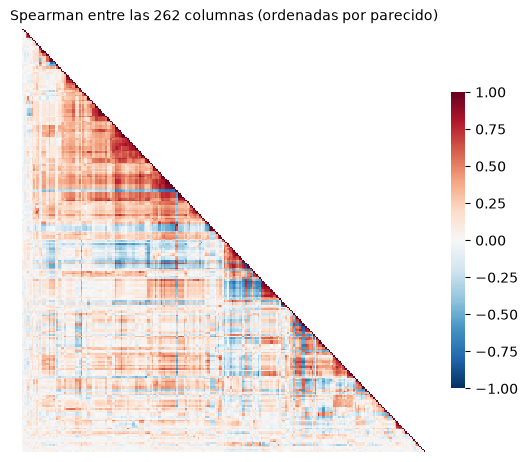

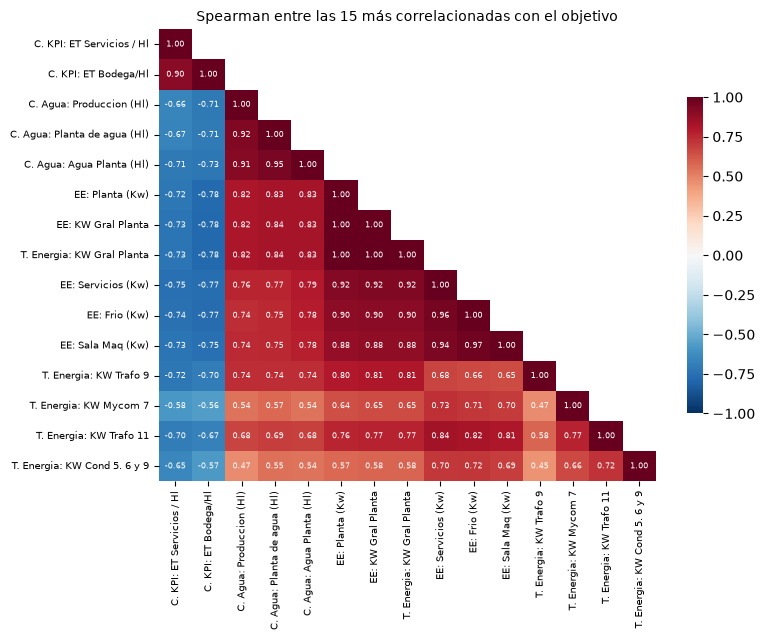

In [73]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from auxiliar_functions import etiqueta_corta, ordenar_por_similitud, parejas_muy_correlacionadas

parejas = parejas_muy_correlacionadas(filas_correlacion, columnas_conservadas, umbral=0.9)

# Una pareja es una "copia" si las dos columnas se llaman igual y están en hojas distintas
nombre_sin_hoja = lambda columna: str(columna).rpartition(" | ")[2].strip()
parejas["Misma columna en dos hojas"] = [nombre_sin_hoja(a) == nombre_sin_hoja(b)
                                         for a, b in zip(parejas["Columna A"], parejas["Columna B"])]
columnas_con_gemela = set(parejas["Columna A"]) | set(parejas["Columna B"])

print("Parejas de columnas muy parecidas entre sí (Spearman en valor absoluto)")
resumen_parejas = pd.DataFrame({"Cantidad": {
    "Parejas con 0,9 o más": len(parejas),
    "Parejas con 0,98 o más": int((parejas["Spearman"].abs() >= 0.98).sum()),
    "Parejas de la misma columna repetida en dos hojas (de las de 0,9 o más)": int(parejas["Misma columna en dos hojas"].sum()),
    "Parejas con distinto nombre (de las de 0,9 o más)": int((~parejas["Misma columna en dos hojas"]).sum()),
    "Columnas con al menos una pareja de 0,9 o más": len(columnas_con_gemela),
    "Columnas conservadas": len(columnas_conservadas)}})
display(tabla_simple(resumen_parejas, precision=0))

print("Las 15 parejas más parecidas entre columnas con distinto nombre")
distintas = parejas[~parejas["Misma columna en dos hojas"]].drop(columns="Misma columna en dos hojas")
display(tabla_simple(distintas.head(15), precision=3))

# Mapa de calor 1: todas las columnas, ordenadas por parecido y solo con el triángulo de abajo
matriz_completa = filas_correlacion[columnas_conservadas].apply(pd.to_numeric, errors="coerce").corr(method="spearman")
ordenada = ordenar_por_similitud(matriz_completa)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(ordenada, mask=np.triu(np.ones(ordenada.shape, dtype=bool), k=1), cmap="RdBu_r", vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Spearman entre las 262 columnas (ordenadas por parecido)", fontsize=10)
plt.show()

# Mapa de calor 2: las 15 más correlacionadas con el objetivo, con los valores escritos
quince = correlaciones.head(15).index.tolist()
de_quince = ordenar_por_similitud(matriz_completa.loc[quince, quince])
de_quince.index = de_quince.columns = [etiqueta_corta(c) for c in de_quince.index]
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(de_quince, mask=np.triu(np.ones(de_quince.shape, dtype=bool), k=1), cmap="RdBu_r", vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 6}, cbar_kws={"shrink": 0.7}, ax=ax)
ax.tick_params(labelsize=7)
ax.set_title("Spearman entre las 15 más correlacionadas con el objetivo", fontsize=10)
plt.tight_layout()
plt.show()


## 23. Distribución del objetivo

Para saber qué forma tiene el consumo de Frio del día siguiente, se grafican su histograma, y su QQ-plot contra una distribución normal, sobre los mismos 817 días válidos del tramo de entrenamiento usados en las correlaciones. La forma importa porque varios modelos y pruebas suponen un objetivo parecido a una distribución gaussiana, y porque los baselines y las correlaciones medidas hasta acá dependen de si la mayoría de los días se concentra en un rango o hay colas largas; junto con los gráficos se calculan la asimetría y la curtosis, que nos aportan más infor respecto a si la forma se aleja de una normal, y una prueba de normalidad de Shapiro-Wilk como contraste.


Resumen del objetivo en el tramo de entrenamiento (kW por día)


,Valor
Días,817.00
Promedio,24773.07
Mediana,25558.00
Desvío estándar,7802.03
Mínimo,2310.00
Máximo,48046.00
Asimetría (0 = simétrica),-0.33
Curtosis (0 = como la normal),-0.32
Intervalos del histograma,20.00


Prueba de normalidad de Shapiro-Wilk: p = 1.1e-06 (alpha = 0.05)


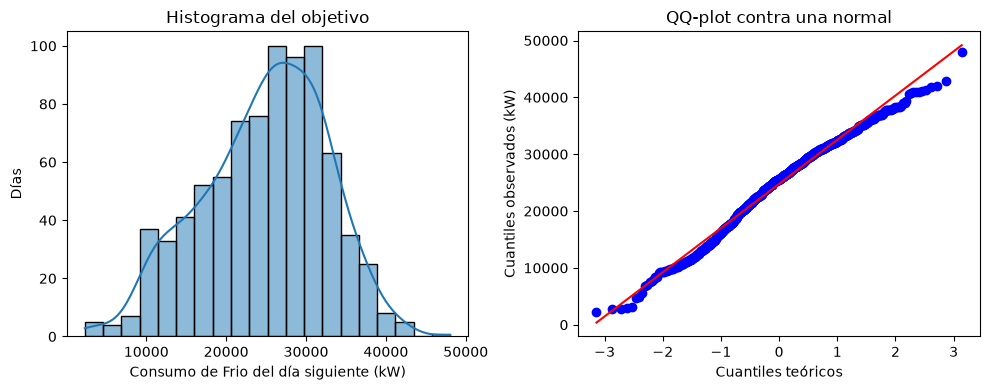

In [75]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats

objetivo_entrenamiento = filas_correlacion["objetivo"]       # 817 días válidos de entrenamiento con objetivo
cantidad_de_bins = len(np.histogram_bin_edges(objetivo_entrenamiento, bins="auto")) - 1   # los que elige NumPy

print("Resumen del objetivo en el tramo de entrenamiento (kW por día)")
resumen_objetivo = pd.DataFrame({"Valor": {
    "Días": len(objetivo_entrenamiento),
    "Promedio": objetivo_entrenamiento.mean(),
    "Mediana": objetivo_entrenamiento.median(),
    "Desvío estándar": objetivo_entrenamiento.std(),
    "Mínimo": objetivo_entrenamiento.min(),
    "Máximo": objetivo_entrenamiento.max(),
    "Asimetría (0 = simétrica)": stats.skew(objetivo_entrenamiento),
    "Curtosis (0 = como la normal)": stats.kurtosis(objetivo_entrenamiento),
    "Intervalos del histograma": cantidad_de_bins}})
display(tabla_simple(resumen_objetivo, precision=2))

p_shapiro = stats.shapiro(objetivo_entrenamiento).pvalue
print(f"Prueba de normalidad de Shapiro-Wilk: p = {p_shapiro:.1e} (alpha = 0.05)")

fig, (ax_histograma, ax_qq) = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(objetivo_entrenamiento, bins="auto", kde=True, ax=ax_histograma)   # kde: curva suavizada encima
ax_histograma.set_title("Histograma del objetivo")
ax_histograma.set_xlabel("Consumo de Frio del día siguiente (kW)")
ax_histograma.set_ylabel("Días")
stats.probplot(objetivo_entrenamiento, dist="norm", plot=ax_qq)               # puntos observados contra la recta normal
ax_qq.set_title("QQ-plot contra una normal")
ax_qq.set_xlabel("Cuantiles teóricos")
ax_qq.set_ylabel("Cuantiles observados (kW)")
plt.tight_layout()
plt.show()


## 24. Las cinco variables más correlacionadas con el objetivo, sin repetir la misma señal

Para ver cómo se relaciona con el objetivo cada una de las mejores variables, se grafican las cinco primeras del ranking de la sección 21 sin repetir la misma señal: se recorre el ranking de mayor a menor Spearman y se saltea toda columna cuya correlación con una ya elegida llega a 0,98, el nivel con el que la consigna advierte que dos variables miden el mismo sistema, de modo que las copias de una misma columna en dos hojas no ocupen dos de los cinco lugares. Cada gráfico muestra el valor de hoy de la variable frente al consumo de mañana, con la vista recortada entre los percentiles 0,5 y 99,5 y un margen, porque unos pocos valores se ubican en el rango de los millones, vistos en la sección 21, aplastarían al resto, y avisa en el eje cuántos días quedaron fuera de la vista.


Las 5 variables más correlacionadas con el objetivo, sin repetir la misma señal


,Spearman,Pearson
Frio (Kw),0.847,0.859
Sala Maq (Kw),0.821,0.005
Servicios (Kw),0.818,0.821
Totalizadores Energia | KW Gral Planta,0.780,0.049
Consolidado KPI | ET Bodega/Hl,-0.721,-0.180


Variables mejor rankeadas que se saltearon por ser copia de una elegida (Spearman de 0,98 o más)


,Spearman,Pearson
KW Gral Planta,0.780,0.049
Planta (Kw),0.774,0.047


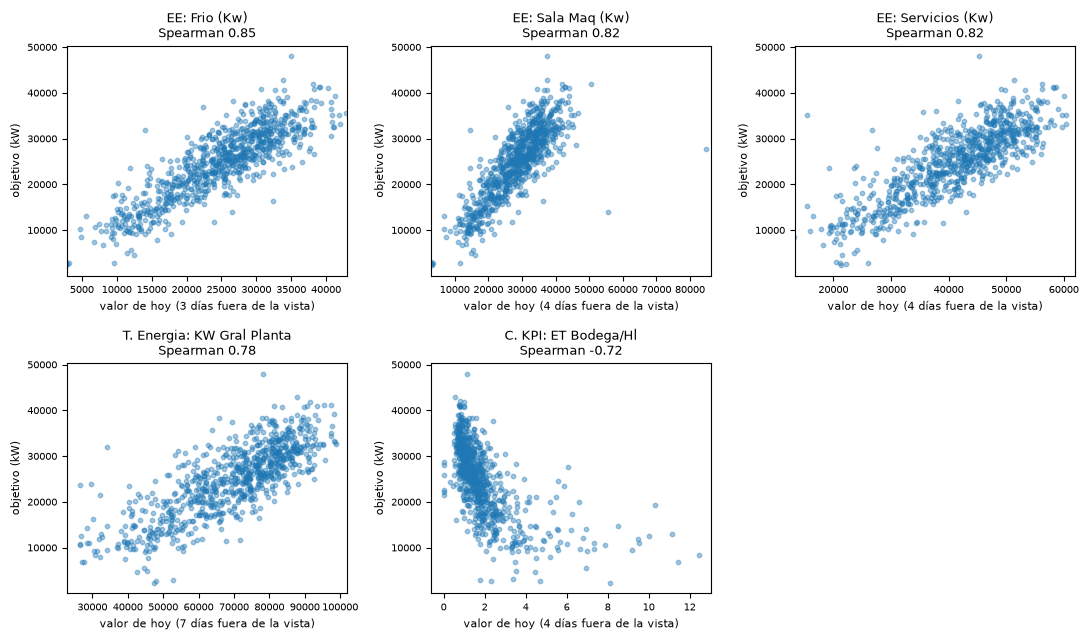

In [76]:
from auxiliar_functions import elegir_columnas_distintas, etiqueta_corta

cinco = elegir_columnas_distintas(correlaciones.index, matriz_completa, cantidad=5, umbral=0.98)
# Las del ranking que quedaron antes de la última elegida y se saltearon por ser copia de otra
saltadas = [c for c in correlaciones.index[: correlaciones.index.get_loc(cinco[-1]) + 1] if c not in cinco]

print("Las 5 variables más correlacionadas con el objetivo, sin repetir la misma señal")
display(tabla_simple(correlaciones.loc[cinco, ["Spearman", "Pearson"]], precision=3))
print("Variables mejor rankeadas que se saltearon por ser copia de una elegida (Spearman de 0,98 o más)")
display(tabla_simple(correlaciones.loc[saltadas, ["Spearman", "Pearson"]], precision=3))

fig, ejes = plt.subplots(2, 3, figsize=(11, 6.5))
ejes = ejes.ravel()                                          # una lista plana de los 6 casilleros
for eje, columna in zip(ejes, cinco):
    valores = pd.to_numeric(filas_correlacion[columna], errors="coerce")
    # Vista entre los percentiles 0,5 y 99,5 más un margen, para que los valores absurdos no aplasten el gráfico
    bajo, alto = valores.quantile([0.005, 0.995])
    margen = (alto - bajo) * 0.05
    eje.scatter(valores, filas_correlacion["objetivo"], s=10, alpha=0.4)
    eje.set_xlim(bajo - margen, alto + margen)
    fuera = int(((valores < bajo - margen) | (valores > alto + margen)).sum())
    eje.set_title(f"{etiqueta_corta(columna)}\nSpearman {correlaciones.loc[columna, 'Spearman']:.2f}", fontsize=9)
    eje.set_xlabel("valor de hoy" + (f" ({fuera} días fuera de la vista)" if fuera else ""), fontsize=8)
    eje.set_ylabel("objetivo (kW)", fontsize=8)
    eje.tick_params(labelsize=7)
for eje in ejes[len(cinco):]:
    eje.axis("off")                                          # el sexto casillero queda vacío
plt.tight_layout()
plt.show()


## 25. Consumo por área de la planta y peso del frío

Esta sección responde dos preguntas: cómo se reparte el consumo eléctrico entre las áreas de la planta y qué parte se lleva el frío. Para la primera se toma, en cada área de Consolidado EE, el consumo diario típico (la mediana de los días válidos, que no se deja distorsionar por los valores de millones que aparecieron en la sección 21) y se muestran por separado las cuatro áreas que suman el total de la planta (Servicios, Envasado, Elaboración y Restos Planta) y las partes de Servicios, donde el frío resulta la mayor; en esta última tabla los porcentajes suman más de 100 porque la columna Sala Maq parece incluir al frío, de modo que ambas cuentan lo mismo dos veces. Para la segunda pregunta se calcula, día por día, qué porcentaje del consumo de la planta corresponde al frío y se observa cómo cambia de mes en mes y según la época del año: si ese porcentaje fuera constante, el frío dependería solo de cuánto trabaja la planta, y si cambia con la estación, hay algo más (como el calor) que lo influye, lo que justificaría evaluar datos de temperatura.


Consumo diario mediano por área de la planta (kW por día, 1187 días válidos; planta: 66,806)


,Mediana diaria (kW),% de la planta
Servicios (Kw),38956.0,58.3
Envasado (Kw),16408.0,24.6
Elaboracion (Kw),7125.0,10.7
Restos Planta (Kw),3574.1,5.3


Consumo diario mediano dentro de Servicios (kW por día; Servicios: 38,956)


,Mediana diaria (kW),% de Servicios
Sala Maq (Kw): subtotal que incluye al frío,26750.0,68.7
Frio (Kw),23655.0,60.7
Aire (Kw),6534.0,16.8
Resto Serv (Kw),5138.0,13.2
Pta Agua / Eflu (Kw),1513.0,3.9
Efluentes (Kw),845.0,2.2
Calderas (Kw),509.0,1.3
Prod Agua (Kw),481.0,1.2
"Suma de las partes, sin Sala Maq",38675.0,99.3


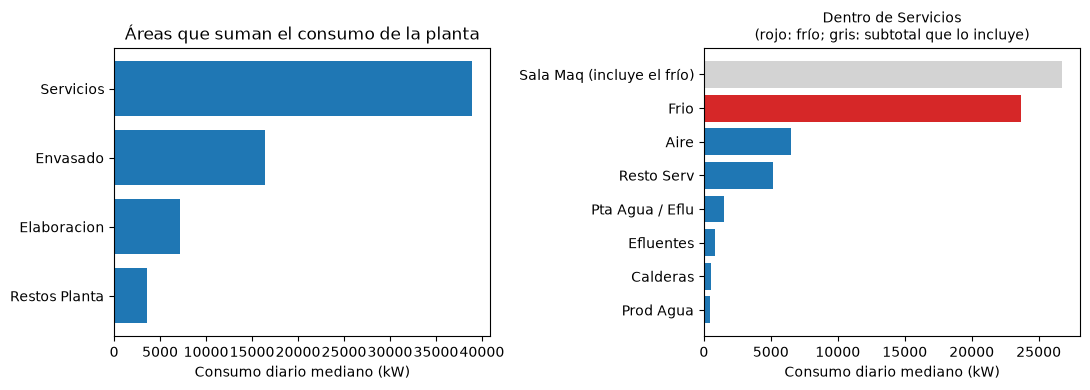

In [78]:
import matplotlib.pyplot as plt

# Todos los días válidos: es una descripción de cómo está repartido el consumo, no una selección de variables
dias_validos = tabla_dia[tabla_dia["valido"]]
mediana_diaria = lambda columna: pd.to_numeric(dias_validos[columna], errors="coerce").median()

areas_de_la_planta = ["Servicios (Kw)", "Envasado (Kw)", "Elaboracion (Kw)", "Restos Planta (Kw)"]
dentro_de_servicios = ["Sala Maq (Kw)", "Frio (Kw)", "Aire (Kw)", "Resto Serv (Kw)",
                       "Pta Agua / Eflu (Kw)", "Efluentes (Kw)", "Calderas (Kw)", "Prod Agua (Kw)"]
mediana_planta = mediana_diaria("Planta (Kw)")
mediana_servicios = mediana_diaria("Servicios (Kw)")
areas = pd.Series({c: mediana_diaria(c) for c in areas_de_la_planta}).sort_values()
interior = pd.Series({c: mediana_diaria(c) for c in dentro_de_servicios}).sort_values()

print(f"Consumo diario mediano por área de la planta (kW por día, {len(dias_validos)} días válidos; planta: {mediana_planta:,.0f})")
tabla_areas = pd.DataFrame({"Mediana diaria (kW)": areas, "% de la planta": 100 * areas / mediana_planta})
display(tabla_simple(tabla_areas.sort_values("Mediana diaria (kW)", ascending=False), precision=1))
print(f"Consumo diario mediano dentro de Servicios (kW por día; Servicios: {mediana_servicios:,.0f})")
tabla_interior = pd.DataFrame({"Mediana diaria (kW)": interior, "% de Servicios": 100 * interior / mediana_servicios})
tabla_interior = tabla_interior.sort_values("Mediana diaria (kW)", ascending=False)
tabla_interior = tabla_interior.rename(index={"Sala Maq (Kw)": "Sala Maq (Kw): subtotal que incluye al frío"})
# Sala Maq no es una parte más de Servicios: se superpone con el frío. Las partes que sí suman son las demás
partes = interior.drop("Sala Maq (Kw)")
tabla_interior.loc["Suma de las partes, sin Sala Maq"] = [partes.sum(), 100 * partes.sum() / mediana_servicios]
display(tabla_simple(tabla_interior, precision=1))

fig, (eje_areas, eje_interior) = plt.subplots(1, 2, figsize=(11, 4))
eje_areas.barh([c.replace(" (Kw)", "") for c in areas.index], areas.values)
eje_areas.set_title("Áreas que suman el consumo de la planta")
colores = ["tab:red" if c == "Frio (Kw)" else "lightgray" if c == "Sala Maq (Kw)" else "tab:blue" for c in interior.index]
etiquetas = ["Sala Maq (incluye el frío)" if c == "Sala Maq (Kw)" else c.replace(" (Kw)", "") for c in interior.index]
eje_interior.barh(etiquetas, interior.values, color=colores)
eje_interior.set_title("Dentro de Servicios\n(rojo: frío; gris: subtotal que lo incluye)", fontsize=10)
for eje in (eje_areas, eje_interior):
    eje.set_xlabel("Consumo diario mediano (kW)")
plt.tight_layout()
plt.show()



## 26. Checksums: huellas de los archivos de datos

Para poder comprobar que cualquiera que clone el repositorio trabaja con exactamente los mismos datos, se calcula la huella SHA-256 de los tres Excel originales y del dataset unificado inicial (la tabla `mejores` de la sección 11, con una fila por día, guardada como CSV antes de agregarle ninguna marca de validez ni el objetivo), leyendo cada archivo por bloques de 1 MiB con la función que nos dan en el TP, y se guardan en data/checksums.json como pares archivo-huella; el JSON queda en el repositorio aunque los Excel no, y la Fase 2 le sumará la huella del dataset final. Se usa SHA-256 y no MD5 porque para MD5 se conocen colisiones (se pueden fabricar dos archivos distintos con el mismo resumen), de modo que no garantiza que un archivo no fue alterado. Como control, al volver a ejecutar la sección se comparan primero el CSV regenerado y los Excel contra las huellas registradas en la corrida anterior, y la celda se detiene si alguno no coincide, porque una huella que cambia al repetir el proceso no serviría para verificar nada.



In [80]:
from auxiliar_functions import guardar_huellas, verificar_huellas

# Dataset unificado inicial: una fila por día, tal como quedó después de unir los tres Excel (sección 11)
ruta_unificado = DATA_DIR / "processed" / "dataset_unificado_inicial.csv"
ruta_unificado.parent.mkdir(exist_ok=True)
mejores.to_csv(ruta_unificado, index=False, encoding="utf-8", lineterminator="\n")   # saltos fijos: misma huella en cualquier sistema

ruta_checksums = DATA_DIR / "checksums.json"
if ruta_checksums.exists():
    # Hay huellas de una corrida anterior: se comparan ANTES de guardar las nuevas. Si el CSV recién generado
    # o algún Excel no coincide, algo cambió respecto de lo registrado y no se pisan las huellas viejas.
    print("Control contra las huellas de la corrida anterior (Excel y CSV recién generado)")
    estado_previo = verificar_huellas(ruta_checksums, DATA_DIR)
    display(tabla_simple(pd.DataFrame({"Estado": estado_previo})))
    assert all(estado == "coincide" for estado in estado_previo.values()), \
        "Algún archivo no coincide con su huella registrada. Si el cambio es esperado, borrar su entrada de data/checksums.json."
else:
    print("Primera corrida: no hay huellas previas con las que comparar")

huellas = guardar_huellas([*archivos, ruta_unificado], ruta_checksums, base=DATA_DIR)

print("Huellas SHA-256 guardadas en data/checksums.json (primeros 16 caracteres)")
tabla_huellas = pd.DataFrame({"Huella (inicio)": {nombre: valor[:16] + "…" for nombre, valor in huellas.items()}})
display(tabla_simple(tabla_huellas))
print(f"Dataset unificado inicial: {len(mejores)} filas, {mejores.shape[1]} columnas, {ruta_unificado.stat().st_size / 1024:.0f} KB")


Control contra las huellas de la corrida anterior (Excel y CSV recién generado)


,Estado
Totalizadores Planta 2020-2022.xlsx,coincide
Totalizadores Planta 2021-2023.xlsx,coincide
Totalizadores Planta 2022-2023.xlsx,coincide
processed/dataset_unificado_inicial.csv,coincide


Huellas SHA-256 guardadas en data/checksums.json (primeros 16 caracteres)


,Huella (inicio)
Totalizadores Planta 2020-2022.xlsx,7bb3474c1686712e…
Totalizadores Planta 2021-2023.xlsx,b4dbfacd0fd8d772…
Totalizadores Planta 2022-2023.xlsx,aba9f9ff11e6fa47…
processed/dataset_unificado_inicial.csv,859f1aa24c749f5d…


Dataset unificado inicial: 1212 filas, 29 columnas, 242 KB
